In [4]:
# %% [markdown]
# # Fig. 3b and Fig. 4a Hippo/program panels
#
# This notebook/script builds a set of Illustrator-editable SVG panels for the revised manuscript outline:
#
# **Fig. 3b**: regulator-effect correlations linking D2 branch programs to D3 EC/alternative endpoint programs.  
# **Fig. 4a**: Hippo-specific perturb-seq KD and small-molecule effects on selected D2/D3 programs, plus collapsed marker category effects.
#
# The plotting code uses source tables only. It does not require loading large `.h5ad` files.

# %%
from __future__ import annotations

from pathlib import Path
import math
import re
from typing import Iterable

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Circle

try:
    from openpyxl import load_workbook
except Exception:
    load_workbook = None

mpl.rcParams.update({
    "font.family": "DejaVu Sans",  # change to Arial on Sherlock if available
    "font.size": 7,
    "figure.dpi": 160,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",  # keep text editable in Illustrator
})

# %% [markdown]
# ## Inputs and selected program sets

# %%
# Output directory
OUT_DIR = Path("/scratch/users/edtng/20260325_Hippo_timecourse/fig3b_fig4a_hippo_panels")
LOCAL_OUT_DIR = Path("/mnt/data/fig3b_fig4a_hippo_panels")
if Path("/scratch/users/edtng").exists():
    FIG_DIR = OUT_DIR
else:
    FIG_DIR = LOCAL_OUT_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

# cNMF workbook with Program Loadings and Perturbation Association 1 sheets.
CNMF_WORKBOOK_CANDIDATES = [
    Path("/scratch/users/edtng/20260325_Hippo_timecourse/cNMF_50_0_2_032526_6co.xlsx"),
    Path("/mnt/data/cNMF_50_0_2_032526_6co.xlsx"),
]

# D3 EC endpoint percentage by target.
# Supports either:
#   1. long format: one row per target × biorep, e.g. d3_EC_percent_by_target_biorep_long.csv
#   2. wide format: one row per target, with replicate-specific count columns
D3_EC_PERCENT_CANDIDATES = [
    Path("/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/d3_EC_percent_by_target_biorep/d3_EC_percent_by_target_biorep_long.csv"),
    Path("/scratch/users/edtng/20260325_Hippo_timecourse/d3_EC_percent_by_target_biorep_long.csv"),
    Path("/scratch/users/edtng/20260325_Hippo_timecourse/d3_EC_percent_by_target_biorep_wide.csv"),
    Path("/mnt/data/d3_EC_percent_by_target_biorep_long.csv"),
    Path("/mnt/data/d3_EC_percent_by_target_biorep_wide.csv"),
]

# Small-molecule program effect tables. Prefer CLR-matched effects if present.
SMALL_MOL_CLR_EFFECT_CANDIDATES = [
    Path("/scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_matched_DE/program_score_DE_clr/small_molecule_projected_cNMF_CLR_matched_effects.tsv"),
    Path("/mnt/data/small_molecule_projected_cNMF_CLR_matched_effects.tsv"),
]

# Fallback normalized-usage effect table if CLR table is not available.
SMALL_MOL_NORM_EFFECT_CANDIDATES = [
    Path("/scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_matched_DE/program_score_DE/projected_cNMF_program_score_matched_contrasts.tsv"),
    Path("/mnt/data/tmp_fig_inputs/hippo_publication_plots_package/source_tables/projected_cNMF_program_score_matched_contrasts.tsv"),
]

# Marker collapsed category tables from the marker-gene analysis.
MARKER_CATEGORY_SUMMARY_CANDIDATES = [
    Path("/scratch/users/edtng/20260325_Hippo_timecourse/marker_gene_control_centered_plots/F_latest_collapsed_marker_category_delta_summary.tsv"),
    Path("/mnt/data/F_latest_collapsed_marker_category_delta_summary.tsv"),
]
MARKER_CATEGORY_REPLICATES_CANDIDATES = [
    Path("/scratch/users/edtng/20260325_Hippo_timecourse/marker_gene_control_centered_plots/F_latest_collapsed_marker_category_delta_replicates.tsv"),
    Path("/mnt/data/F_latest_collapsed_marker_category_delta_replicates.tsv"),
]

# Program groups for the panels. Adjust these as annotations evolve.
D2_BRANCH_PROGRAMS = ["P13", "P30", "P14", "P15", "P17", "P19", "P23"]
D2_CORE_PROGRAMS_FOR_HEATMAP = ["P14", "P15", "P17", "P19", "P23"]
D3_EC_PROGRAMS = ["P2", "P3", "P8", "P11", "P42"]
D3_ALT_PROGRAMS = ["P16", "P24", "P27", "P33", "P34", "P35"]
SELECTED_PROGRAMS = D2_CORE_PROGRAMS_FOR_HEATMAP + D3_EC_PROGRAMS + D3_ALT_PROGRAMS
KEY_PROGRAMS = ["P15", "P17", "P34", "P2", "P23", "P24"]

HIPPO_KD_TARGETS = ["LATS2", "NF2", "SAV1", "TAOK1", "WWC3", "AMOTL2"]
PERTURBSEQ_EFFECT_COL = "approx_log2FC"  # use beta_hat instead if that is your final programDE effect column
CORRELATION_METHOD = "spearman"  # "spearman" or "pearson"

# Small molecule contrasts shown in Fig. 4a.
SMALL_MOL_CONTRAST_ORDER = [
    "D2_LM+TDI",
    "D2_LM+IAG",
    "D3_AE+TDI",
    "D3_AE+IAG",
    "D2_LM+TDI->D3_AE+TDI",
    "D2_LM+IAG->D3_AE+IAG",
]

print("Output directory:", FIG_DIR)

# %% [markdown]
# ## Helper functions

# %%
def find_existing(candidates: Iterable[Path], required: bool = True, label: str = "file") -> Path | None:
    for p in candidates:
        if p.exists():
            return p
    if required:
        raise FileNotFoundError(f"Could not find {label}. Tried: {[str(p) for p in candidates]}")
    return None


def load_d3_ec_endpoint(path: Path) -> tuple[pd.Series, pd.DataFrame]:
    """Load D3 EC% endpoint table in either long or wide format.

    Long format expected columns:
        target, replicate, n_target_carrier_cells, n_EC_target_carrier_cells,
        optionally pct_EC_target_carrier_cells

    Wide format expected columns:
        target and one or more columns ending with n_target_carrier_cells and
        n_EC_target_carrier_cells.

    Returns
    -------
    endpoint_series
        Series indexed by target with weighted D3 EC percent.
    endpoint_summary
        DataFrame with one row per target and counts used for weighting.
    """
    ec = pd.read_csv(path)
    if "target" not in ec.columns:
        # Allow common variants if someone exports with target_name instead.
        if "target_name" in ec.columns:
            ec = ec.rename(columns={"target_name": "target"})
        else:
            raise ValueError(f"D3 EC endpoint table must contain `target` or `target_name`. Columns: {list(ec.columns)}")

    ec["target"] = ec["target"].astype(str)

    # Long format: one row per target x replicate.
    if {"n_target_carrier_cells", "n_EC_target_carrier_cells"}.issubset(ec.columns):
        grouped = (
            ec.groupby("target", as_index=False)
            .agg(
                n_carrier_total=("n_target_carrier_cells", "sum"),
                n_ec_total=("n_EC_target_carrier_cells", "sum"),
                n_bioreps=("target", "size"),
            )
        )
        # Optional simple mean of per-replicate percentages, useful as QC.
        if "pct_EC_target_carrier_cells" in ec.columns:
            mean_pct = (
                ec.groupby("target")["pct_EC_target_carrier_cells"]
                .mean()
                .rename("d3_ec_percent_mean_of_bioreps")
                .reset_index()
            )
            grouped = grouped.merge(mean_pct, on="target", how="left")

    # Wide format: one row per target with replicate-specific columns.
    else:
        carrier_cols = [c for c in ec.columns if str(c).endswith("n_target_carrier_cells")]
        ec_cols = [c for c in ec.columns if str(c).endswith("n_EC_target_carrier_cells")]
        if not carrier_cols or not ec_cols:
            # Also allow a precomputed percentage-only table, if needed.
            pct_candidates = [c for c in ec.columns if str(c).lower() in {"d3_ec_percent", "d3_ec_percent_weighted", "pct_ec"}]
            if pct_candidates:
                pct_col = pct_candidates[0]
                grouped = ec[["target", pct_col]].copy()
                grouped = grouped.rename(columns={pct_col: "d3_ec_percent_weighted"})
                grouped["n_carrier_total"] = np.nan
                grouped["n_ec_total"] = np.nan
                grouped["n_bioreps"] = np.nan
                endpoint = grouped.set_index("target")["d3_ec_percent_weighted"].rename("D3 EC %")
                return endpoint, grouped
            raise ValueError(
                "Could not identify D3 EC endpoint columns. Expected long columns "
                "`n_target_carrier_cells` and `n_EC_target_carrier_cells`, or wide columns ending with those names. "
                f"Columns: {list(ec.columns)}"
            )
        grouped = ec[["target"]].copy()
        grouped["n_carrier_total"] = ec[carrier_cols].sum(axis=1)
        grouped["n_ec_total"] = ec[ec_cols].sum(axis=1)
        grouped["n_bioreps"] = len(carrier_cols)

    grouped["d3_ec_percent_weighted"] = 100 * grouped["n_ec_total"] / grouped["n_carrier_total"].replace(0, np.nan)
    endpoint = grouped.set_index("target")["d3_ec_percent_weighted"].rename("D3 EC %")
    return endpoint, grouped


def read_xlsx_sheet_fast(path: Path, sheet_name: str) -> pd.DataFrame:
    """Read one xlsx sheet using openpyxl read-only mode; drops the leading unnamed index column."""
    if load_workbook is None:
        return pd.read_excel(path, sheet_name=sheet_name)
    wb = load_workbook(path, read_only=True, data_only=True)
    try:
        ws = wb[sheet_name]
        rows = ws.iter_rows(values_only=True)
        header = list(next(rows))
        data = list(rows)
    finally:
        wb.close()
    df = pd.DataFrame(data, columns=header)
    # Drop completely empty rows and columns, and the leading unnamed index column if present.
    df = df.dropna(axis=0, how="all").dropna(axis=1, how="all")
    unnamed = [c for c in df.columns if c is None or str(c).startswith("Unnamed")]
    if unnamed:
        df = df.drop(columns=unnamed)
    return df


def read_perturbation_assoc_subset(path: Path, sheet_name: str, samples, programs, effect_col: str) -> pd.DataFrame:
    """Stream-filter Perturbation Association sheet to selected samples/programs."""
    if load_workbook is None:
        df = pd.read_excel(path, sheet_name=sheet_name)
        df = df.copy()
        unnamed = [c for c in df.columns if c is None or str(c).startswith("Unnamed")]
        if unnamed:
            df = df.drop(columns=unnamed)
        df["program"] = "P" + df["program_name"].map(program_to_int).astype(str)
        df[effect_col] = pd.to_numeric(df[effect_col], errors="coerce")
        return df[df["Sample"].astype(str).isin(samples) & df["program"].isin(programs)]

    sample_set = set(map(str, samples))
    program_set = set(map(str, programs))
    wb = load_workbook(path, read_only=True, data_only=True)
    ws = wb[sheet_name]
    rows = ws.iter_rows(values_only=True)
    header = list(next(rows))
    col = {str(name): idx for idx, name in enumerate(header) if name is not None}
    required = ["target_name", "program_name", "Sample", effect_col]
    missing = [x for x in required if x not in col]
    if missing:
        raise ValueError(f"Missing required columns {missing} from {sheet_name}; header={header}")

    out = []
    for row in rows:
        if row is None or all(v is None for v in row):
            continue
        sample = str(row[col["Sample"]])
        if sample not in sample_set:
            continue
        try:
            pid = program_to_int(row[col["program_name"]])
        except Exception:
            continue
        program = f"P{pid}"
        if program not in program_set:
            continue
        out.append({
            "target_name": str(row[col["target_name"]]),
            "program_name": str(row[col["program_name"]]),
            "program": program,
            "program_id": pid,
            "Sample": sample,
            effect_col: row[col[effect_col]],
        })
    df = pd.DataFrame(out)
    if len(df):
        df[effect_col] = pd.to_numeric(df[effect_col], errors="coerce")
    return df


def program_to_int(program: str | int | float) -> int:
    s = str(program).replace("P", "").strip()
    return int(float(s))


def program_sort_key(program: str) -> int:
    return program_to_int(program)


def label_program(program: str, labels: dict[str, str] | None = None, max_chars: int = 38) -> str:
    if labels is None or program not in labels or not labels[program]:
        return program
    label = str(labels[program]).strip()
    out = f"{program}: {label}"
    if len(out) > max_chars:
        out = out[: max_chars - 1].rstrip() + "…"
    return out


def add_program_groups_to_ylabels(programs, labels, group_map):
    out = []
    last_group = None
    for p in programs:
        group = group_map.get(p, "")
        prefix = ""
        if group != last_group:
            prefix = f"{group}\n" if group else ""
        out.append(prefix + label_program(p, labels, max_chars=34))
        last_group = group
    return out


def corr_pair(a: pd.Series, b: pd.Series, method: str = "spearman"):
    m = pd.concat([a, b], axis=1, join="inner").dropna()
    if m.shape[0] < 3:
        return np.nan, np.nan, m.shape[0]
    if method == "spearman":
        r, p = spearmanr(m.iloc[:, 0], m.iloc[:, 1])
    elif method == "pearson":
        r, p = pearsonr(m.iloc[:, 0], m.iloc[:, 1])
    else:
        raise ValueError(method)
    return float(r), float(p), int(m.shape[0])


def effect_vector(prog_df: pd.DataFrame, program: str, day: str, effect_col: str = PERTURBSEQ_EFFECT_COL) -> pd.Series:
    pid = program_to_int(program)
    sub = prog_df.loc[(prog_df["program"] == f"P{pid}") & (prog_df["Sample"].astype(str) == day), ["target_name", effect_col]]
    return sub.dropna().groupby("target_name")[effect_col].mean().rename(f"{program}_{day}")


def plot_matrix_heatmap(df: pd.DataFrame, title: str, out_prefix: Path, cmap="RdBu_r", center_zero=True,
                        annotate=True, x_rotation=45, y_fontsize=7, vlim=None, figsize=None):
    mat = df.to_numpy(dtype=float)
    n_rows, n_cols = mat.shape
    if vlim is not None:
        vmin, vmax = (-vlim, vlim) if center_zero else (np.nanmin(mat), vlim)
    elif center_zero:
        vmax = np.nanmax(np.abs(mat))
        vmin = -vmax
    else:
        vmin = np.nanmin(mat)
        vmax = np.nanmax(mat)
        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-9

    if figsize is None:
        figsize = (max(5, 0.45 * n_cols + 2.5), max(4, 0.28 * n_rows + 1.5))

    fig, ax = plt.subplots(figsize=figsize)
    mesh = ax.pcolormesh(
        np.arange(n_cols + 1), np.arange(n_rows + 1), mat,
        cmap=cmap, vmin=vmin, vmax=vmax, shading="flat",
        linewidth=0, antialiased=False,
    )
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_xticks(np.arange(n_cols) + 0.5)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_xticklabels(df.columns, rotation=x_rotation, ha="right" if x_rotation else "center")
    ax.set_yticklabels(df.index, fontsize=y_fontsize)
    ax.set_title(title)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if annotate:
        for i in range(n_rows):
            for j in range(n_cols):
                val = mat[i, j]
                if np.isfinite(val):
                    ax.text(j + 0.5, i + 0.5, f"{val:.2f}", ha="center", va="center", fontsize=5)
    cbar = fig.colorbar(mesh, ax=ax, pad=0.02)
    cbar.ax.tick_params(labelsize=6)
    fig.tight_layout()
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(out_prefix.with_suffix(f".{ext}"), bbox_inches="tight", dpi=300 if ext == "png" else None)
    plt.close(fig)


def save_table(df: pd.DataFrame, name: str):
    path = FIG_DIR / name
    df.to_csv(path, sep="\t", index=True)
    return path

# %% [markdown]
# ## Load cNMF programDE workbook and endpoint data

# %%
cnmf_workbook = find_existing(CNMF_WORKBOOK_CANDIDATES, label="cNMF workbook")
d3_ec_path = find_existing(D3_EC_PERCENT_CANDIDATES, required=False, label="D3 EC endpoint table")
print("cNMF workbook:", cnmf_workbook)
print("D3 EC endpoint table:", d3_ec_path)

# Only D2/D3 and selected programs are needed for the panels.
assoc = read_perturbation_assoc_subset(
    cnmf_workbook,
    "Perturbation Association 1",
    samples=["D2", "D3"],
    programs=SELECTED_PROGRAMS + D2_BRANCH_PROGRAMS,
    effect_col=PERTURBSEQ_EFFECT_COL,
)
assoc = assoc.copy()
assoc["target_name"] = assoc["target_name"].astype(str)
assoc["Sample"] = assoc["Sample"].astype(str)
print("assoc subset shape:", assoc.shape)
print("samples:", sorted(assoc["Sample"].unique()))
print("programs:", sorted(assoc["program"].unique(), key=program_sort_key)[:5], "...", sorted(assoc["program"].unique(), key=program_sort_key)[-5:])

# Program labels from Program Loadings are not ideal; use manual descriptions here.
PROGRAM_LABELS = {
    "P13": "early/branch program",
    "P30": "early/branch program",
    "P14": "lateral mesoderm",
    "P15": "vascular progenitor",
    "P17": "epithelial/alt LM",
    "P19": "posterior mesoderm",
    "P23": "vascular LM / EC induction",
    "P2": "arterial endothelium",
    "P3": "activated endothelium",
    "P8": "EC adhesion/Notch",
    "P11": "angiogenic EC",
    "P42": "vascular signaling",
    "P16": "cytoskeletal/alt",
    "P24": "GATA4/RSPO2 alt",
    "P27": "mesenchymal ECM",
    "P33": "anterior-like mesoderm",
    "P34": "YAP/mesenchymal",
    "P35": "EMT/ECM",
}
PROGRAM_GROUP = {p: "D2 branch" for p in D2_CORE_PROGRAMS_FOR_HEATMAP}
PROGRAM_GROUP.update({p: "D3 EC" for p in D3_EC_PROGRAMS})
PROGRAM_GROUP.update({p: "D3 alternative" for p in D3_ALT_PROGRAMS})

# %% [markdown]
# ## Fig. 3b: D2 branch programs vs D3 EC/alternative programs and endpoint

# %%
# Build a D3 EC endpoint vector, if the endpoint table is available.
ec_endpoint = None
if d3_ec_path is not None:
    ec_endpoint, ec_endpoint_summary = load_d3_ec_endpoint(d3_ec_path)
    ec_endpoint_summary.to_csv(
        FIG_DIR / "D3_EC_percent_endpoint_weighted_by_target.tsv", sep="\t", index=False
    )
    print("EC endpoint targets:", ec_endpoint.shape[0])
    print("EC endpoint summary columns:", list(ec_endpoint_summary.columns))
    print(ec_endpoint_summary.head())

rows = []
fig3b_mat = pd.DataFrame(index=D2_BRANCH_PROGRAMS)
fig3b_p_mat = pd.DataFrame(index=D2_BRANCH_PROGRAMS)

fig3b_cols = D3_EC_PROGRAMS + D3_ALT_PROGRAMS + (["D3 EC %"] if ec_endpoint is not None else [])

for p_d2 in D2_BRANCH_PROGRAMS:
    a = effect_vector(assoc, p_d2, "D2")
    vals = []
    pvals = []
    for p_d3 in D3_EC_PROGRAMS + D3_ALT_PROGRAMS:
        b = effect_vector(assoc, p_d3, "D3")
        r, p, n = corr_pair(a, b, CORRELATION_METHOD)
        vals.append(r)
        pvals.append(p)
        rows.append({
            "source_day": "D2",
            "source_program": p_d2,
            "target_day": "D3",
            "target_program": p_d3,
            "target_type": "D3 EC program" if p_d3 in D3_EC_PROGRAMS else "D3 alternative program",
            "method": CORRELATION_METHOD,
            "correlation": r,
            "pvalue": p,
            "n_targets": n,
        })
    if ec_endpoint is not None:
        r, p, n = corr_pair(a, ec_endpoint, CORRELATION_METHOD)
        vals.append(r)
        pvals.append(p)
        rows.append({
            "source_day": "D2",
            "source_program": p_d2,
            "target_day": "D3",
            "target_program": "D3 EC %",
            "target_type": "D3 endpoint",
            "method": CORRELATION_METHOD,
            "correlation": r,
            "pvalue": p,
            "n_targets": n,
        })
    fig3b_mat.loc[p_d2, fig3b_cols] = vals
    fig3b_p_mat.loc[p_d2, fig3b_cols] = pvals

fig3b_edges = pd.DataFrame(rows)
fig3b_edges.to_csv(FIG_DIR / "Fig3b_D2_to_D3_program_endpoint_correlations.tsv", sep="\t", index=False)
fig3b_mat.to_csv(FIG_DIR / "Fig3b_D2_to_D3_program_endpoint_correlation_matrix.tsv", sep="\t")

# Heatmap labels.
fig3b_mat_labeled = fig3b_mat.copy()
fig3b_mat_labeled.index = [label_program(p, PROGRAM_LABELS, 32) for p in fig3b_mat.index]
fig3b_mat_labeled.columns = [label_program(c, PROGRAM_LABELS, 30) if c.startswith("P") else c for c in fig3b_mat.columns]

plot_matrix_heatmap(
    fig3b_mat_labeled,
    title=f"Fig. 3b candidate: D2 program effects correlated with D3 programs/endpoints\n{CORRELATION_METHOD.capitalize()} correlation across perturbation targets",
    out_prefix=FIG_DIR / "Fig3b_D2_branch_vs_D3_program_endpoint_correlation_heatmap",
    cmap="RdBu_r",
    center_zero=True,
    annotate=True,
    x_rotation=45,
    y_fontsize=7,
    figsize=(9.5, 4.2),
)

# %% [markdown]
# ## Optional Fig. 3b network/schematic from the same edge table

# %%
def plot_transition_network(edge_df: pd.DataFrame, out_prefix: Path, threshold=0.45):
    # Draw all biologically selected edges among P15/P17/P2/P34/D3 EC%, plus thresholded edges.
    forced = (
        edge_df["source_program"].isin(["P15", "P17"]) &
        edge_df["target_program"].isin(["P2", "P34", "D3 EC %"])
    ) | (
        edge_df["target_program"].isin(["P2", "P34", "D3 EC %"]) &
        (edge_df["correlation"].abs() >= 0.35)
    )
    plot_edges = edge_df.loc[(edge_df["correlation"].abs() >= threshold) | forced].copy()

    d2_nodes = D2_BRANCH_PROGRAMS
    d3_nodes = D3_EC_PROGRAMS + D3_ALT_PROGRAMS
    if "D3 EC %" in edge_df["target_program"].values:
        endpoint_nodes = ["D3 EC %"]
    else:
        endpoint_nodes = []

    pos = {}
    for i, node in enumerate(d2_nodes):
        pos[node] = (0, i)
    for i, node in enumerate(d3_nodes):
        pos[node] = (1.7, i * (len(d2_nodes)-1) / max(1, len(d3_nodes)-1))
    for i, node in enumerate(endpoint_nodes):
        pos[node] = (3.4, (len(d2_nodes)-1)/2)

    fig, ax = plt.subplots(figsize=(7.8, 4.8))
    # Edges
    for _, row in plot_edges.iterrows():
        src = row["source_program"]
        tgt = row["target_program"]
        if src not in pos or tgt not in pos:
            continue
        x1, y1 = pos[src]
        x2, y2 = pos[tgt]
        r = row["correlation"]
        color = "#c0392b" if r >= 0 else "#2166ac"
        lw = 0.5 + 3.0 * min(1, abs(r))
        ax.plot([x1, x2], [y1, y2], color=color, linewidth=lw, alpha=0.7)
        if src in ["P15", "P17"] and tgt in ["P2", "P34", "D3 EC %"]:
            ax.text((x1+x2)/2, (y1+y2)/2, f"r={r:.2f}", fontsize=5, ha="center", va="center")

    # Nodes
    for node, (x, y) in pos.items():
        if node in D2_BRANCH_PROGRAMS:
            face = "#f2f2f2"
        elif node in D3_EC_PROGRAMS:
            face = "#e6f2ff"
        elif node in D3_ALT_PROGRAMS:
            face = "#fff0e6"
        else:
            face = "#e8f5e9"
        circ = Circle((x, y), 0.12, facecolor=face, edgecolor="black", linewidth=0.8)
        ax.add_patch(circ)
        ax.text(x, y+0.19, label_program(node, PROGRAM_LABELS, 18), fontsize=6, ha="center", va="bottom")

    ax.text(0, -0.8, "D2 branch programs", ha="center", fontsize=8, weight="bold")
    ax.text(1.7, -0.8, "D3 programs", ha="center", fontsize=8, weight="bold")
    if endpoint_nodes:
        ax.text(3.4, -0.8, "Endpoint", ha="center", fontsize=8, weight="bold")
    ax.set_xlim(-0.5, 3.9)
    ax.set_ylim(len(d2_nodes)-0.2, -1.1)
    ax.axis("off")
    fig.tight_layout()
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(out_prefix.with_suffix(f".{ext}"), dpi=300 if ext == "png" else None)
    plt.close(fig)

plot_transition_network(fig3b_edges, FIG_DIR / "Fig3b_selected_program_transition_network", threshold=0.50)

# %% [markdown]
# ## Fig. 4a-1: Hippo KD effects on selected programs in perturb-seq

# %%
hippo = assoc.loc[assoc["target_name"].isin(HIPPO_KD_TARGETS)].copy()
hippo = hippo.loc[hippo["Sample"].isin(["D2", "D3"])]

# Individual Hippo KD target heatmap: rows target/day, columns selected programs.
hippo_rows = []
for day in ["D2", "D3"]:
    for target in HIPPO_KD_TARGETS:
        sub = hippo.loc[(hippo["Sample"] == day) & (hippo["target_name"] == target)]
        vals = []
        for p in SELECTED_PROGRAMS:
            v = sub.loc[sub["program"] == p, PERTURBSEQ_EFFECT_COL]
            vals.append(float(v.mean()) if len(v) else np.nan)
        hippo_rows.append(pd.Series(vals, index=SELECTED_PROGRAMS, name=f"{day} {target}"))
hippo_individual_mat = pd.DataFrame(hippo_rows)
hippo_individual_mat.to_csv(FIG_DIR / "Fig4a_HippoKD_individual_targets_selected_program_effects.tsv", sep="\t")

# Mean Hippo KD effect across targets.
hippo_mean_rows = []
for day in ["D2", "D3"]:
    sub = hippo.loc[hippo["Sample"] == day]
    means = sub.groupby("program")[PERTURBSEQ_EFFECT_COL].mean()
    hippo_mean_rows.append(means.reindex(SELECTED_PROGRAMS).rename(f"Hippo KD mean {day}"))
hippo_mean_mat = pd.DataFrame(hippo_mean_rows)
hippo_mean_mat.to_csv(FIG_DIR / "Fig4a_HippoKD_mean_selected_program_effects.tsv", sep="\t")

selected_display_cols = [label_program(p, PROGRAM_LABELS, 26) for p in SELECTED_PROGRAMS]
hippo_indiv_plot = hippo_individual_mat.copy()
hippo_indiv_plot.columns = selected_display_cols

plot_matrix_heatmap(
    hippo_indiv_plot,
    title=f"Fig. 4a candidate: perturb-seq Hippo KD effects on selected programs\nEffect column: {PERTURBSEQ_EFFECT_COL}",
    out_prefix=FIG_DIR / "Fig4a_HippoKD_individual_targets_selected_program_effects_heatmap",
    cmap="RdBu_r",
    center_zero=True,
    annotate=False,
    x_rotation=50,
    y_fontsize=6,
    figsize=(11, 5.5),
)

hippo_mean_plot = hippo_mean_mat.copy()
hippo_mean_plot.columns = selected_display_cols
plot_matrix_heatmap(
    hippo_mean_plot,
    title=f"Fig. 4a candidate: mean Hippo KD effects on selected programs\nAveraged across {len(HIPPO_KD_TARGETS)} Hippo targets",
    out_prefix=FIG_DIR / "Fig4a_HippoKD_mean_selected_program_effects_heatmap",
    cmap="RdBu_r",
    center_zero=True,
    annotate=True,
    x_rotation=50,
    y_fontsize=7,
    figsize=(11, 2.6),
)

# %% [markdown]
# ## Fig. 4a-2: Small-molecule effects on the same selected programs

# %%
sm_effect_path = find_existing(SMALL_MOL_CLR_EFFECT_CANDIDATES, required=False, label="small-molecule CLR effects")
sm_effect_source = "CLR"
if sm_effect_path is None:
    sm_effect_path = find_existing(SMALL_MOL_NORM_EFFECT_CANDIDATES, required=False, label="small-molecule normalized usage effects")
    sm_effect_source = "normalized_usage_difference"
print("Small-molecule effect source:", sm_effect_source if sm_effect_path is not None else "not found")
print("Small-molecule effect table:", sm_effect_path)

if sm_effect_path is not None:
    sm = pd.read_csv(sm_effect_path, sep="\t")
    # Harmonize columns.
    if sm_effect_source == "CLR":
        effect_col = "mean_diff_clr"
        if "treated_condition" not in sm.columns and "contrast" in sm.columns:
            sm["treated_condition"] = sm["contrast"]
    else:
        candidates = ["diff_treated_minus_control", "mean_diff", "mean_diff_usage", "mean_paired_diff"]
        effect_col = next((c for c in candidates if c in sm.columns), None)
        if effect_col is None:
            raise ValueError(f"Could not infer small-molecule effect column. Columns: {list(sm.columns)}")

    if effect_col not in sm.columns:
        raise ValueError(f"Expected effect column {effect_col!r} in {sm_effect_path}. Columns: {list(sm.columns)}")

    if "treated_condition" not in sm.columns:
        if "contrast" in sm.columns:
            sm["treated_condition"] = sm["contrast"]
        elif "contrast_name" in sm.columns:
            sm["treated_condition"] = sm["contrast_name"]
        else:
            raise ValueError("Could not identify treated condition column in small-molecule effect table")

    sm["treated_condition"] = sm["treated_condition"].astype(str).map(lambda x: {
        "TDI_at_D2_LM": "D2_LM+TDI",
        "IAG_at_D2_LM": "D2_LM+IAG",
        "TDI_at_D3_AE": "D3_AE+TDI",
        "IAG_at_D3_AE": "D3_AE+IAG",
        "TDI_D2_to_D3_vs_D3_AE": "D2_LM+TDI->D3_AE+TDI",
        "IAG_D2_to_D3_vs_D3_AE": "D2_LM+IAG->D3_AE+IAG",
    }.get(x, x))

    sm_rows = []
    for treated in SMALL_MOL_CONTRAST_ORDER:
        sub = sm.loc[sm["treated_condition"] == treated]
        vals = []
        for p in SELECTED_PROGRAMS:
            v = sub.loc[sub["program"].astype(str) == p, effect_col]
            vals.append(float(v.mean()) if len(v) else np.nan)
        sm_rows.append(pd.Series(vals, index=SELECTED_PROGRAMS, name=treated))
    sm_mat = pd.DataFrame(sm_rows)
    sm_mat.to_csv(FIG_DIR / f"Fig4a_small_molecule_{sm_effect_source}_selected_program_effects.tsv", sep="\t")

    sm_plot = sm_mat.copy()
    sm_plot.columns = selected_display_cols
    plot_matrix_heatmap(
        sm_plot,
        title=f"Fig. 4a candidate: TDI/IAG effects on selected projected programs\nScale: {sm_effect_source}; values are treated - matched control",
        out_prefix=FIG_DIR / f"Fig4a_small_molecule_{sm_effect_source}_selected_program_effects_heatmap",
        cmap="RdBu_r",
        center_zero=True,
        annotate=True,
        x_rotation=50,
        y_fontsize=7,
        figsize=(11, 4.2),
    )
else:
    print("Small-molecule program-effect table not found; skipped Fig4a TDI/IAG selected-program heatmap.")

# %% [markdown]
# ## Fig. 4a-3: Collapsed marker category treatment effect plot
#
# This uses the already computed control-centered marker module category table if present.

# %%
marker_summary_path = find_existing(MARKER_CATEGORY_SUMMARY_CANDIDATES, required=False, label="marker category summary")
marker_rep_path = find_existing(MARKER_CATEGORY_REPLICATES_CANDIDATES, required=False, label="marker category replicate table")
print("marker summary:", marker_summary_path)
print("marker replicate:", marker_rep_path)

if marker_summary_path is not None and marker_rep_path is not None:
    marker_summary = pd.read_csv(marker_summary_path, sep="\t")
    marker_rep = pd.read_csv(marker_rep_path, sep="\t")

    # Normalize contrast names for order.
    contrast_order_short = ["D2 TDI", "D2 IAG", "D3 TDI", "D3 IAG", "D2→D3 TDI", "D2→D3 IAG"]
    category_order = ["EC/progenitor markers", "Alternative/YAP markers"]
    category_short = {"EC/progenitor markers": "EC / progenitor", "Alternative/YAP markers": "Alternative / YAP"}

    marker_rep = marker_rep.loc[marker_rep["contrast"].isin(contrast_order_short)].copy()
    marker_summary = marker_summary.loc[marker_summary["contrast"].isin(contrast_order_short)].copy()

    x_positions = {}
    xs = []
    labels = []
    spacing = 1.1
    dx = 0.18
    for i, contrast in enumerate(contrast_order_short):
        for cat_j, cat in enumerate(category_order):
            x = i * spacing + (-dx if cat_j == 0 else dx)
            x_positions[(contrast, cat)] = x
        xs.append(i * spacing)
        labels.append(contrast)

    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    # replicate points
    for _, row in marker_rep.iterrows():
        key = (row["contrast"], row["category"])
        if key not in x_positions:
            continue
        x = x_positions[key]
        jitter = (int(row["replicate"]) - 2) * 0.025 if "replicate" in row and pd.notna(row["replicate"]) else 0
        marker = "o" if row["category"] == "EC/progenitor markers" else "s"
        ax.scatter(x + jitter, row["mean_delta_log2cpm"], s=18, marker=marker, facecolors="white", edgecolors="black", linewidth=0.6, zorder=3)

    # means and connecting lines between categories within each contrast.
    for contrast in contrast_order_short:
        sub = marker_summary.loc[marker_summary["contrast"] == contrast]
        vals = {}
        for _, row in sub.iterrows():
            vals[row["category"]] = row["mean"]
        if all(cat in vals for cat in category_order):
            x1 = x_positions[(contrast, category_order[0])]
            x2 = x_positions[(contrast, category_order[1])]
            y1 = vals[category_order[0]]
            y2 = vals[category_order[1]]
            ax.plot([x1, x2], [y1, y2], color="0.35", linewidth=1.0, zorder=2)
            ax.scatter([x1, x2], [y1, y2], s=50, marker="D", color="black", zorder=4)

    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_xticks(xs)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_ylabel("Matched-control Δ marker module log2(CPM+1)")
    ax.set_title("Fig. 4a candidate: collapsed marker categories\nEC/progenitor vs Alternative/YAP, matched-control centered")
    legend_handles = [
        Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="white", markeredgecolor="black", label="EC / progenitor"),
        Line2D([0], [0], marker="s", linestyle="none", markerfacecolor="white", markeredgecolor="black", label="Alternative / YAP"),
        Line2D([0], [0], marker="D", linestyle="none", color="black", label="mean"),
    ]
    ax.legend(handles=legend_handles, frameon=False, fontsize=6, loc="best")
    fig.tight_layout()
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(FIG_DIR / f"Fig4a_marker_category_collapsed_control_centered.{ext}", dpi=300 if ext == "png" else None, bbox_inches="tight")
    plt.close(fig)
else:
    print("Skipping marker category plot because marker summary/replicate tables are not available.")

# %% [markdown]
# ## Optional combined preview: Fig. 4a triptych
#
# This combines mean Hippo KD, small-molecule effect, and marker category summary. It is intended as a draft layout only.

# %%
# Save a README/source summary.
summary = {
    "CNMF workbook": str(cnmf_workbook),
    "D3 EC endpoint table": str(d3_ec_path) if d3_ec_path is not None else "not found",
    "Small molecule effect source": sm_effect_source,
    "Small molecule effect table": str(sm_effect_path),
    "Marker summary": str(marker_summary_path) if marker_summary_path is not None else "not found",
    "Marker replicate": str(marker_rep_path) if marker_rep_path is not None else "not found",
    "Perturbseq effect column": PERTURBSEQ_EFFECT_COL,
    "Hippo targets": ";".join(HIPPO_KD_TARGETS),
    "Selected programs": ";".join(SELECTED_PROGRAMS),
}
with open(FIG_DIR / "figure_panel_generation_summary.txt", "w") as f:
    for k, v in summary.items():
        f.write(f"{k}: {v}\n")

print("Saved figure panels to:", FIG_DIR)
for p in sorted(FIG_DIR.glob("*")):
    print(p.name)


Output directory: /scratch/users/edtng/20260325_Hippo_timecourse/fig3b_fig4a_hippo_panels
cNMF workbook: /scratch/users/edtng/20260325_Hippo_timecourse/cNMF_50_0_2_032526_6co.xlsx
D3 EC endpoint table: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/d3_EC_percent_by_target_biorep/d3_EC_percent_by_target_biorep_long.csv
assoc subset shape: (10764, 6)
samples: ['D2', 'D3']
programs: ['P2', 'P3', 'P8', 'P11', 'P13'] ... ['P30', 'P33', 'P34', 'P35', 'P42']
EC endpoint targets: 298
EC endpoint summary columns: ['target', 'n_carrier_total', 'n_ec_total', 'n_bioreps', 'd3_ec_percent_mean_of_bioreps', 'd3_ec_percent_weighted']
   target  n_carrier_total  n_ec_total  n_bioreps  \
0   ACAA1              634         361          2   
1  ACTL7B              638         328          2   
2  ACVR1B              639         243          2   
3  ACVR2A              585         175          2   
4  ACVR2B              621         235          2   

   d3_ec_percent_mean_of_bioreps 

#### More panels

AnnData object with n_obs × n_vars = 212891 × 62757
    obs: 'guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 'biological_sample', 'plate', 'sublibID', 'sample_name', 'perturbseq_cNMF_P0_usage', 'perturbseq_cNMF_P1_usage', 'perturbseq_cNMF_P2_usage', 'perturbseq_cNMF_P3_usage', 'perturbseq_cNMF_P4_usage', 'perturbseq_cNMF_P5_usage', 'perturbseq_cNMF_P6_usage', 'perturbseq_cNMF_P7_usage', 'perturbseq_cNMF_P8_usage', 'perturbseq_cNMF_P9_usage', 'perturbseq_cNMF_P10_usage', 'perturbseq_cNMF_P11_usage', 'perturbseq_cNMF_P12_usage', 'perturbseq_cNMF_P13_usage', 'perturbseq_cNMF_P14_usage', 'perturbseq_cNMF_P15_usage', 'perturbseq_cNMF_P16_usage', 'perturbseq_cNMF_P17_usage', 'perturbseq_cNMF_P18_usage', 'perturbseq_cNMF_P19_usage', 'perturbseq_cNMF_P20_usage', 'perturbseq_cNMF_P21_usage', 'perturbseq_cNMF_P22_usage', 'perturbseq_cNMF_P23_usage', 'perturbseq_cNMF_P24_usage

,perturbseq_day,program,perturbseq_HippoKD_mean_effect,perturbseq_HippoKD_sd,n_targets
0,D2,P11,0.088282,0.581400,6
1,D2,P14,-0.412884,1.212772,6
2,D2,P15,-1.066264,0.697568,6
3,D2,P16,-0.149442,0.510091,6
4,D2,P17,1.234523,0.853522,6


small molecule effect source: Small-molecule CLR effect


,contrast,treatment,control_condition,treated_condition,program,n_matched_pairs,mean_control_clr,mean_treated_clr,mean_diff_clr,sd_diff_clr,paired_t_stat,paired_t_pvalue,n_positive_diffs,n_negative_diffs
302,D2_LM+TDI,TDI,D2_LM,D2_LM+TDI,P2,3,-1.990522,-2.067199,-0.076676,0.126352,-1.051087,0.403483,1,2
303,D2_LM+TDI,TDI,D2_LM,D2_LM+TDI,P3,3,-2.152347,-2.229465,-0.077118,0.133909,-0.997494,0.423615,1,2
308,D2_LM+TDI,TDI,D2_LM,D2_LM+TDI,P8,3,5.295060,6.283786,0.988726,3.450624,0.496294,0.668866,1,2
311,D2_LM+TDI,TDI,D2_LM,D2_LM+TDI,P11,3,-2.099931,-2.174900,-0.074969,0.144403,-0.899225,0.463434,1,2
314,D2_LM+TDI,TDI,D2_LM,D2_LM+TDI,P14,3,0.729166,1.435565,0.706399,0.641688,1.906719,0.196812,2,1


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

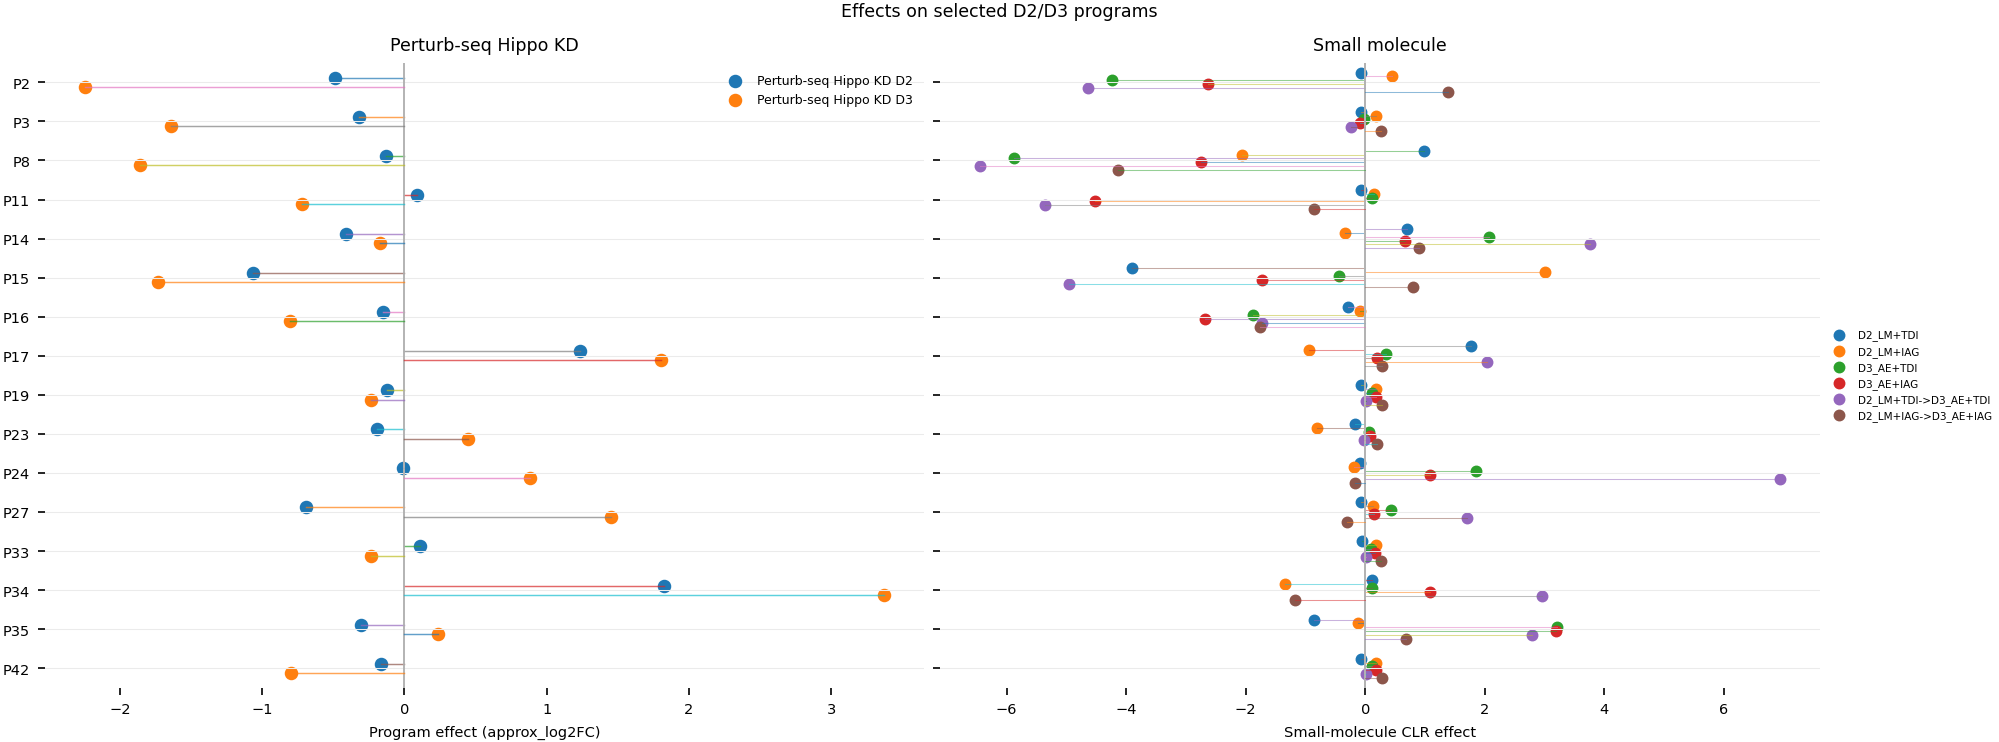

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

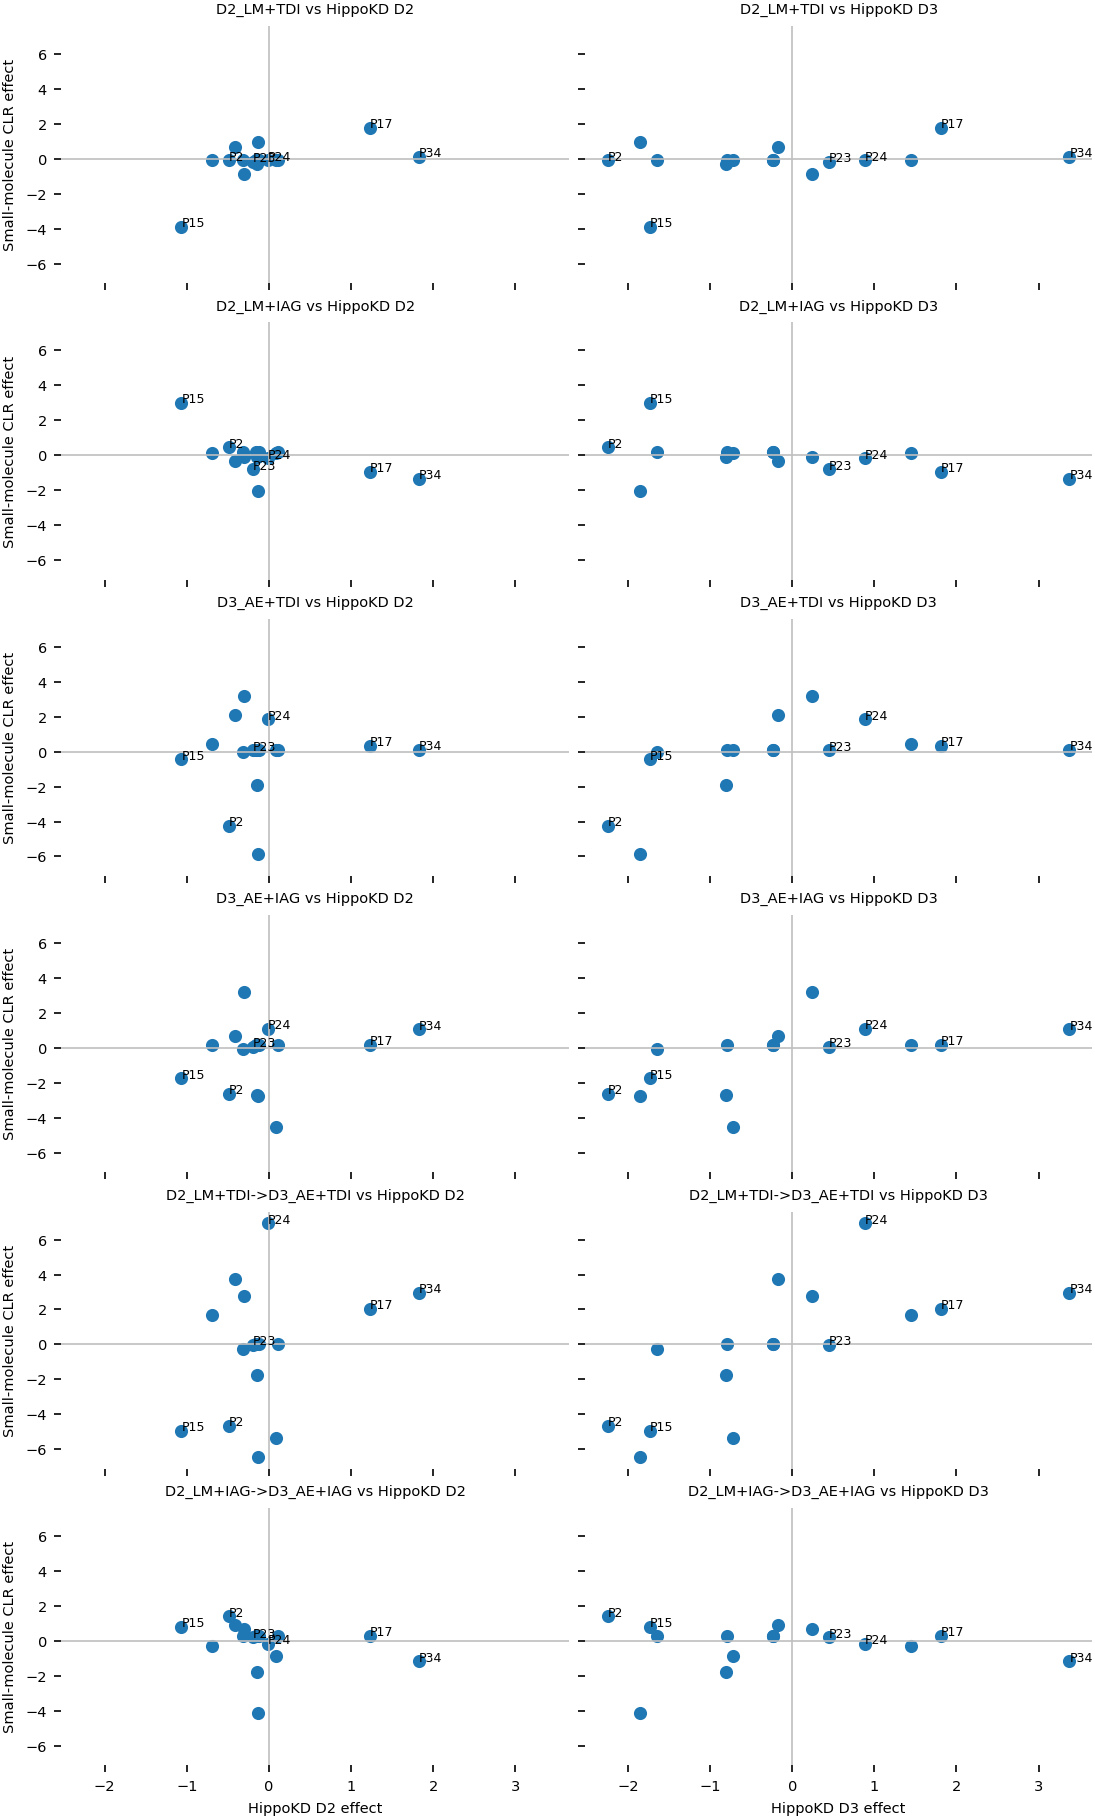

Saved outputs to: /scratch/users/edtng/20260325_Hippo_timecourse/hippo_umap_and_effect_comparison_panels
Fig4a_program_effect_dotpanel_HippoKD_vs_small_molecule_selected_programs.svg
Fig4a_small_molecule_vs_HippoKD_selected_program_scatter_D2_D3_refs.svg


In [5]:
# %% [markdown]
# # Hippo UMAP + effect-comparison panels
#
# This notebook/script makes figure candidates that are less heatmap-heavy:
#
# 1. UMAP feature panels for projected perturb-seq cNMF programs and representative marker genes/modules.
# 2. Dot/lollipop panels comparing small-molecule effects to perturb-seq Hippo CRISPRi effects on selected programs.
#
# The cNMF workbook path is set to the Sherlock location provided by Tri:
# `/scratch/users/edtng/20260325_Hippo_timecourse/cNMF_50_0_2_032526_6co.xlsx`.

# %%
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
from scipy.stats import ttest_rel
import matplotlib as mpl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 7,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",  # keep text editable in Illustrator
})

# %% [markdown]
# ## Paths and user settings

# %%
BASE = Path("/scratch/users/edtng/20260325_Hippo_timecourse")
PROJ_DIR = BASE / "perturbseq_cNMF_projection"
DE_DIR = BASE / "perturbseq_cNMF_matched_DE"

H5AD_PATH = PROJ_DIR / "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"
CNMF_WORKBOOK_PATH = BASE / "cNMF_50_0_2_032526_6co.xlsx"

# Preferred small-molecule effect file: CLR scale to match programDE.
SMALL_MOL_CLR_EFFECT_PATH = DE_DIR / "program_score_DE_clr" / "small_molecule_projected_cNMF_CLR_matched_effects.tsv"
SMALL_MOL_CLR_PAIRED_PATH = DE_DIR / "program_score_DE_clr" / "small_molecule_projected_cNMF_CLR_paired_replicate_differences.tsv"

# Fallback if CLR table does not exist.
SMALL_MOL_SCORE_EFFECT_PATH = DE_DIR / "program_score_DE" / "projected_cNMF_program_score_matched_contrasts.tsv"
SMALL_MOL_SCORE_PAIRED_PATH = DE_DIR / "program_score_DE" / "projected_cNMF_program_score_paired_replicate_differences.tsv"

OUT_DIR = BASE / "hippo_umap_and_effect_comparison_panels"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Relevant programs. Adjust if Kyle/Hunter annotation changes.
D2_PROGRAMS = ["P14", "P15", "P17", "P19", "P23"]
D3_EC_PROGRAMS = ["P2", "P3", "P8", "P11", "P42"]
D3_ALT_PROGRAMS = ["P16", "P24", "P27", "P33", "P34", "P35"]
SELECTED_PROGRAMS = D2_PROGRAMS + D3_EC_PROGRAMS + D3_ALT_PROGRAMS
KEY_PROGRAMS = ["P15", "P17", "P23", "P2", "P34", "P24"]

HIPPO_KD_TARGETS = ["LATS2", "NF2", "SAV1", "TAOK1", "WWC3", "AMOTL2"]
PROGRAM_ASSOC_SHEET = "Perturbation Association 1"
PERTURBSEQ_EFFECT_COL = "approx_log2FC"  # use beta_hat if preferred

# Conditions for UMAP and treatment-effect displays.
FOCUS_CONDITIONS = [
    "D2_LM", "D2_LM+TDI", "D2_LM+IAG",
    "D3_AE", "D3_AE+TDI", "D3_AE+IAG",
    "D2_LM+TDI->D3_AE+TDI",
    "D2_LM+IAG->D3_AE+IAG",
]

# UMAP options
UMAP_KEY = "X_umap"
COMPUTE_UMAP_IF_MISSING = False  # turn on only if you want to compute a new UMAP
MAX_CELLS_PER_CONDITION_FOR_UMAP = 8000
RANDOM_SEED = 0
POINT_SIZE = 0.6
POINT_ALPHA = 0.85

# Marker genes/modules for UMAP and marker score panels.
MARKER_PROGRAM_GENES = {
    "P15 vascular progenitor": ["TAL1", "FLI1", "SOX7"],
    "P23 vascular LM/EC induction": ["KDR", "ETV2"],
    "P17 epithelial/LM alt": ["KRT8", "KRT18"],
    "P2 arterial EC": ["MECOM", "NRP1", "EFNB2"],
    "P34 YAP/mesenchyme": ["ANKRD1", "KRT8", "KRT18"],
    "P24 GATA4/RSPO2": ["GATA4", "RSPO2"],
}

# %% [markdown]
# ## Helpers

# %%
def infer_condition_from_sample_name(sample_name: str) -> str:
    """Strip trailing _repN from sample_name to get condition."""
    m = re.match(r"(.+)_rep\d+$", str(sample_name))
    return m.group(1) if m else str(sample_name)


def program_id(program: str) -> int:
    m = re.search(r"(\d+)$", str(program))
    if m is None:
        raise ValueError(f"Cannot parse program id from {program!r}")
    return int(m.group(1))


def sanitize_filename(x: str) -> str:
    x = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(x))
    return re.sub(r"_+", "_", x).strip("_")


def ensure_condition_column(obs: pd.DataFrame) -> pd.DataFrame:
    obs = obs.copy()
    if "condition" not in obs.columns:
        if "sample_name" not in obs.columns:
            raise KeyError("Need either obs['condition'] or obs['sample_name']")
        obs["condition"] = obs["sample_name"].map(infer_condition_from_sample_name)
    obs["condition"] = obs["condition"].astype(str)
    if "sample_name" in obs.columns:
        obs["sample_name"] = obs["sample_name"].astype(str)
    return obs


def get_program_names(adata, usage):
    meta = adata.uns.get("perturbseq_cNMF_projection", {})
    names = []
    if isinstance(meta, dict) and "program_names" in meta:
        names = [str(x) for x in meta["program_names"]]
    if len(names) != usage.shape[1]:
        names = [f"P{i}" for i in range(usage.shape[1])]
    order = np.argsort([program_id(p) for p in names])
    return [names[i] for i in order], order


def get_var_index_for_gene_symbol(adata, symbol: str):
    """Return var index/indices for a gene symbol using adata.var['gene'] if available, else var_names."""
    symbol = str(symbol)
    if "gene" in adata.var.columns:
        matches = np.flatnonzero(adata.var["gene"].astype(str).to_numpy() == symbol)
        if len(matches) > 0:
            return matches.tolist()
    matches = np.flatnonzero(adata.var_names.astype(str).to_numpy() == symbol)
    return matches.tolist()


def get_log2cpm_for_genes(adata, gene_symbols, cell_idx=None):
    """Extract log2(CPM + 1) for a small list of genes without loading all genes."""
    if cell_idx is None:
        cell_idx = np.arange(adata.n_obs)
    total_counts = pd.to_numeric(adata.obs["total_counts"], errors="coerce").to_numpy()[cell_idx]
    total_counts = np.where(total_counts > 0, total_counts, np.nan)

    values = {}
    missing = []
    for gene in gene_symbols:
        var_idx = get_var_index_for_gene_symbol(adata, gene)
        if len(var_idx) == 0:
            missing.append(gene)
            continue
        sub = adata[cell_idx, var_idx].X
        if sparse.issparse(sub):
            arr = np.asarray(sub.sum(axis=1)).ravel()
        else:
            arr = np.asarray(sub).sum(axis=1).ravel()
        cpm = arr / total_counts * 1e6
        values[gene] = np.log2(cpm + 1)
    return pd.DataFrame(values, index=adata.obs_names[cell_idx].astype(str)), missing


def average_marker_module(log2cpm_df: pd.DataFrame, genes):
    present = [g for g in genes if g in log2cpm_df.columns]
    if len(present) == 0:
        return pd.Series(np.nan, index=log2cpm_df.index), []
    return log2cpm_df[present].mean(axis=1), present


def save_fig(fig, out_prefix: Path):
    out_prefix.parent.mkdir(parents=True, exist_ok=True)
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(out_prefix.with_suffix(f".{ext}"), dpi=300 if ext == "png" else None, bbox_inches="tight")

# %% [markdown]
# ## Load projected time-course AnnData

# %%
adata = sc.read_h5ad(H5AD_PATH)
adata.obs = ensure_condition_column(adata.obs)
usage = np.asarray(adata.obsm["X_perturbseq_cNMF_usage"])
program_names, program_order = get_program_names(adata, usage)
usage = usage[:, program_order]
program_to_col = {p: i for i, p in enumerate(program_names)}

print(adata)
print("condition values:", sorted(adata.obs["condition"].unique().tolist()))
print("programs:", program_names[:5], "...", program_names[-5:])
print("UMAP present:", UMAP_KEY in adata.obsm)

# %% [markdown]
# ## Optional: compute UMAP if missing
#
# This can take time. It writes the UMAP back into memory only; save manually if needed.

# %%
if UMAP_KEY not in adata.obsm:
    if not COMPUTE_UMAP_IF_MISSING:
        print(f"No {UMAP_KEY} found. Set COMPUTE_UMAP_IF_MISSING=True to compute one, or add UMAP coordinates to the h5ad.")
    else:
        print("Computing UMAP. This can be slow for 200k+ cells.")
        if "X_pca" not in adata.obsm:
            tmp = adata.copy()
            sc.pp.normalize_total(tmp, target_sum=1e4)
            sc.pp.log1p(tmp)
            sc.pp.highly_variable_genes(tmp, n_top_genes=3000, subset=True)
            sc.pp.scale(tmp, max_value=10)
            sc.tl.pca(tmp, n_comps=50)
            adata.obsm["X_pca"] = tmp.obsm["X_pca"]
        sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=15)
        sc.tl.umap(adata)

# %% [markdown]
# ## UMAP panel: selected programs and marker modules
#
# This makes UMAP feature plots for selected conditions. Points are rasterized to keep SVGs reasonable; text remains editable.

# %%
def downsample_indices_by_condition(obs, conditions, max_per_condition=8000, seed=0):
    rng = np.random.default_rng(seed)
    keep = []
    cond_arr = obs["condition"].astype(str).to_numpy()
    for cond in conditions:
        idx = np.flatnonzero(cond_arr == cond)
        if len(idx) == 0:
            continue
        if len(idx) > max_per_condition:
            idx = rng.choice(idx, size=max_per_condition, replace=False)
        keep.extend(idx.tolist())
    return np.array(sorted(keep), dtype=int)


def plot_umap_feature_facets(feature_values, feature_name, conditions=FOCUS_CONDITIONS, out_prefix=None, cmap="viridis"):
    if UMAP_KEY not in adata.obsm:
        print(f"Skipping {feature_name}: no {UMAP_KEY} in adata.obsm")
        return

    idx = downsample_indices_by_condition(adata.obs, conditions, MAX_CELLS_PER_CONDITION_FOR_UMAP, RANDOM_SEED)
    if len(idx) == 0:
        print("No cells for selected conditions.")
        return

    coords = np.asarray(adata.obsm[UMAP_KEY])[idx]
    values = np.asarray(feature_values)[idx]
    conds = adata.obs["condition"].astype(str).to_numpy()[idx]
    present_conditions = [c for c in conditions if np.any(conds == c)]

    n = len(present_conditions)
    ncols = min(4, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0*ncols, 3.0*nrows), squeeze=False)

    finite = np.isfinite(values)
    vmax = np.nanpercentile(values[finite], 99) if finite.any() else 1
    vmin = np.nanpercentile(values[finite], 1) if finite.any() else 0
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-9

    for ax, cond in zip(axes.ravel(), present_conditions):
        m = conds == cond
        sca = ax.scatter(
            coords[m, 0], coords[m, 1],
            c=values[m],
            s=POINT_SIZE,
            alpha=POINT_ALPHA,
            linewidths=0,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            rasterized=True,
        )
        ax.set_title(cond)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_aspect("equal")

    for ax in axes.ravel()[len(present_conditions):]:
        ax.axis("off")

    fig.suptitle(feature_name, y=1.02)
    cbar = fig.colorbar(sca, ax=axes.ravel().tolist(), fraction=0.02, pad=0.01)
    cbar.set_label(feature_name)
    fig.tight_layout()

    if out_prefix is not None:
        save_fig(fig, out_prefix)
    plt.show()
    plt.close(fig)

# Program UMAPs
for program in ["P15", "P17", "P23", "P2", "P34", "P24"]:
    if program in program_to_col:
        plot_umap_feature_facets(
            usage[:, program_to_col[program]],
            feature_name=f"Projected {program} usage",
            out_prefix=OUT_DIR / "umap_programs" / f"UMAP_projected_{program}_selected_conditions",
        )

# Marker module UMAPs
all_marker_genes = sorted(set(g for genes in MARKER_PROGRAM_GENES.values() for g in genes))
if UMAP_KEY in adata.obsm:
    idx_all = np.arange(adata.n_obs)
    marker_expr, missing_genes = get_log2cpm_for_genes(adata, all_marker_genes, idx_all)
    print("Missing marker genes:", missing_genes)
    for module_name, genes in MARKER_PROGRAM_GENES.items():
        vals, present = average_marker_module(marker_expr, genes)
        print(module_name, "present genes:", present)
        plot_umap_feature_facets(
            vals.to_numpy(),
            feature_name=f"{module_name} marker module log2CPM",
            out_prefix=OUT_DIR / "umap_marker_modules" / f"UMAP_{sanitize_filename(module_name)}_marker_module_selected_conditions",
        )

# %% [markdown]
# ## Load perturb-seq Hippo CRISPRi program effects

# %%
assoc = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name=PROGRAM_ASSOC_SHEET)
assoc = assoc.copy()
assoc["program"] = "P" + assoc["program_name"].astype(int).astype(str)
assoc = assoc[assoc["program"].isin(SELECTED_PROGRAMS)].copy()
assoc = assoc[assoc["target_name"].isin(HIPPO_KD_TARGETS)].copy()
assoc = assoc[assoc["Sample"].isin(["D2", "D3"])].copy()
assoc[PERTURBSEQ_EFFECT_COL] = pd.to_numeric(assoc[PERTURBSEQ_EFFECT_COL], errors="coerce")

print("assoc shape:", assoc.shape)
print("targets:", sorted(assoc["target_name"].unique().tolist()))
print("programs:", sorted(assoc["program"].unique().tolist(), key=program_id))

hippo_effect_individual = (
    assoc.groupby(["Sample", "target_name", "program"], observed=True)[PERTURBSEQ_EFFECT_COL]
    .mean()
    .reset_index()
    .rename(columns={"Sample": "perturbseq_day", PERTURBSEQ_EFFECT_COL: "perturbseq_HippoKD_effect"})
)

hippo_effect_mean = (
    hippo_effect_individual.groupby(["perturbseq_day", "program"], observed=True)["perturbseq_HippoKD_effect"]
    .agg(["mean", "std", "count"])
    .reset_index()
    .rename(columns={"mean": "perturbseq_HippoKD_mean_effect", "std": "perturbseq_HippoKD_sd", "count": "n_targets"})
)

hippo_effect_individual.to_csv(OUT_DIR / "perturbseq_HippoKD_individual_target_effects_selected_programs.tsv", sep="\t", index=False)
hippo_effect_mean.to_csv(OUT_DIR / "perturbseq_HippoKD_mean_effects_selected_programs.tsv", sep="\t", index=False)
display(hippo_effect_mean.head())

# %% [markdown]
# ## Load small-molecule program effects

# %%
if SMALL_MOL_CLR_EFFECT_PATH.exists():
    sm = pd.read_csv(SMALL_MOL_CLR_EFFECT_PATH, sep="\t")
    effect_col = "mean_diff_clr"
    effect_label = "Small-molecule CLR effect"
    paired_path = SMALL_MOL_CLR_PAIRED_PATH
elif SMALL_MOL_SCORE_EFFECT_PATH.exists():
    sm = pd.read_csv(SMALL_MOL_SCORE_EFFECT_PATH, sep="\t")
    effect_col = "mean_diff"
    effect_label = "Small-molecule mean usage difference"
    paired_path = SMALL_MOL_SCORE_PAIRED_PATH
else:
    raise FileNotFoundError("No small-molecule effect table found.")

sm = sm.copy()
sm = sm[sm["program"].isin(SELECTED_PROGRAMS)].copy()
sm[effect_col] = pd.to_numeric(sm[effect_col], errors="coerce")

# Keep contrasts most relevant for Fig. 4a.
contrast_order = [
    "D2_LM+TDI",
    "D2_LM+IAG",
    "D3_AE+TDI",
    "D3_AE+IAG",
    "D2_LM+TDI->D3_AE+TDI",
    "D2_LM+IAG->D3_AE+IAG",
]
sm = sm[sm["contrast"].isin(contrast_order)].copy()
sm["contrast"] = pd.Categorical(sm["contrast"], categories=contrast_order, ordered=True)
sm.to_csv(OUT_DIR / "small_molecule_effects_selected_programs.tsv", sep="\t", index=False)

print("small molecule effect source:", effect_label)
display(sm.head())

# %% [markdown]
# ## Plot: program effects as dot/lollipop comparison, not heatmap

# %%
def plot_effect_dotpanel(hippo_mean, sm_df, out_prefix):
    programs = [p for p in SELECTED_PROGRAMS if p in set(hippo_mean["program"]) or p in set(sm_df["program"])]
    programs = sorted(programs, key=program_id)

    fig, axes = plt.subplots(1, 2, figsize=(13.5, max(5, 0.32*len(programs))), sharey=True)

    y_pos = np.arange(len(programs))

    # Left: perturb-seq Hippo KD mean effects, D2 and D3.
    ax = axes[0]
    for day, offset in [("D2", -0.12), ("D3", 0.12)]:
        sub = hippo_mean[hippo_mean["perturbseq_day"] == day].set_index("program").reindex(programs)
        vals = sub["perturbseq_HippoKD_mean_effect"].to_numpy(dtype=float)
        ax.axvline(0, color="0.7", lw=0.8)
        ax.scatter(vals, y_pos + offset, s=30, label=f"Perturb-seq Hippo KD {day}")
        for y, v in zip(y_pos + offset, vals):
            if np.isfinite(v):
                ax.plot([0, v], [y, y], lw=0.7, alpha=0.7)

    ax.set_title("Perturb-seq Hippo KD")
    ax.set_xlabel(f"Program effect ({PERTURBSEQ_EFFECT_COL})")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(programs)
    ax.legend(frameon=False, fontsize=6)

    # Right: small molecules.
    ax = axes[1]
    offsets = np.linspace(-0.25, 0.25, len(contrast_order))
    for contrast, offset in zip(contrast_order, offsets):
        sub = sm_df[sm_df["contrast"] == contrast].set_index("program").reindex(programs)
        vals = sub[effect_col].to_numpy(dtype=float)
        ax.axvline(0, color="0.7", lw=0.8)
        ax.scatter(vals, y_pos + offset, s=22, label=contrast)
        for y, v in zip(y_pos + offset, vals):
            if np.isfinite(v):
                ax.plot([0, v], [y, y], lw=0.5, alpha=0.5)

    ax.set_title("Small molecule")
    ax.set_xlabel(effect_label)
    ax.legend(frameon=False, fontsize=5, loc="center left", bbox_to_anchor=(1.0, 0.5))

    for ax in axes:
        ax.grid(axis="y", color="0.92", lw=0.5)
        ax.set_ylim(len(programs)-0.5, -0.5)
        for spine in ax.spines.values():
            spine.set_visible(False)

    fig.suptitle("Effects on selected D2/D3 programs")
    fig.tight_layout()
    save_fig(fig, out_prefix)
    plt.show()
    plt.close(fig)

plot_effect_dotpanel(
    hippo_effect_mean,
    sm,
    OUT_DIR / "Fig4a_program_effect_dotpanel_HippoKD_vs_small_molecule_selected_programs",
)

# %% [markdown]
# ## Plot: selected program scatter, small molecule vs perturb-seq Hippo KD

# %%
def plot_smallmol_vs_hippokd_selected_scatter(hippo_mean, sm_df, out_prefix):
    # Compare small molecule against D2 and D3 HippoKD references for selected programs.
    merged_records = []
    for contrast in contrast_order:
        sub_sm = sm_df[sm_df["contrast"] == contrast][["contrast", "program", effect_col]]
        for day in ["D2", "D3"]:
            sub_h = hippo_mean[hippo_mean["perturbseq_day"] == day][["program", "perturbseq_HippoKD_mean_effect"]]
            m = sub_sm.merge(sub_h, on="program", how="inner")
            m["perturbseq_day"] = day
            merged_records.append(m)
    merged = pd.concat(merged_records, ignore_index=True)
    merged.to_csv(OUT_DIR / "small_molecule_vs_HippoKD_selected_program_scatter_values.tsv", sep="\t", index=False)

    nrows = len(contrast_order)
    fig, axes = plt.subplots(nrows, 2, figsize=(7.6, 2.05*nrows), sharex=True, sharey=True)

    for i, contrast in enumerate(contrast_order):
        for j, day in enumerate(["D2", "D3"]):
            ax = axes[i, j]
            sub = merged[(merged["contrast"] == contrast) & (merged["perturbseq_day"] == day)]
            ax.axhline(0, color="0.75", lw=0.8)
            ax.axvline(0, color="0.75", lw=0.8)
            ax.scatter(sub["perturbseq_HippoKD_mean_effect"], sub[effect_col], s=28)
            for _, row in sub.iterrows():
                if row["program"] in KEY_PROGRAMS:
                    ax.text(row["perturbseq_HippoKD_mean_effect"], row[effect_col], row["program"], fontsize=6)
            ax.set_title(f"{contrast} vs HippoKD {day}", fontsize=7)
            if i == nrows - 1:
                ax.set_xlabel(f"HippoKD {day} effect")
            if j == 0:
                ax.set_ylabel(effect_label)
            for spine in ax.spines.values():
                spine.set_visible(False)

    fig.tight_layout()
    save_fig(fig, out_prefix)
    plt.show()
    plt.close(fig)

plot_smallmol_vs_hippokd_selected_scatter(
    hippo_effect_mean,
    sm,
    OUT_DIR / "Fig4a_small_molecule_vs_HippoKD_selected_program_scatter_D2_D3_refs",
)

# %% [markdown]
# ## Optional: UMAP marker/program panels are already saved above if UMAP exists.

# %%
print("Saved outputs to:", OUT_DIR)
for p in sorted(OUT_DIR.glob("*.svg")):
    print(p.name)


#### Additional panels

Output: /scratch/users/edtng/20260325_Hippo_timecourse/hippo_additional_panels
cNMF workbook: /scratch/users/edtng/20260325_Hippo_timecourse/cNMF_50_0_2_032526_6co.xlsx True
DE directory: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_matched_DE/pydeseq2_gene_DE True
CLR effects: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_matched_DE/program_score_DE_clr/small_molecule_projected_cNMF_CLR_matched_effects.tsv True
Projected h5ad: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad True
Loaded DE tables: ['D2_LM+TDI', 'D2_LM+IAG', 'D3_AE+TDI', 'D3_AE+IAG', 'D2_LM+TDI→D3_AE+TDI', 'D2_LM+IAG→D3_AE+IAG']
Program loadings: (15000, 6)
Spectra: (50, 17538)


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

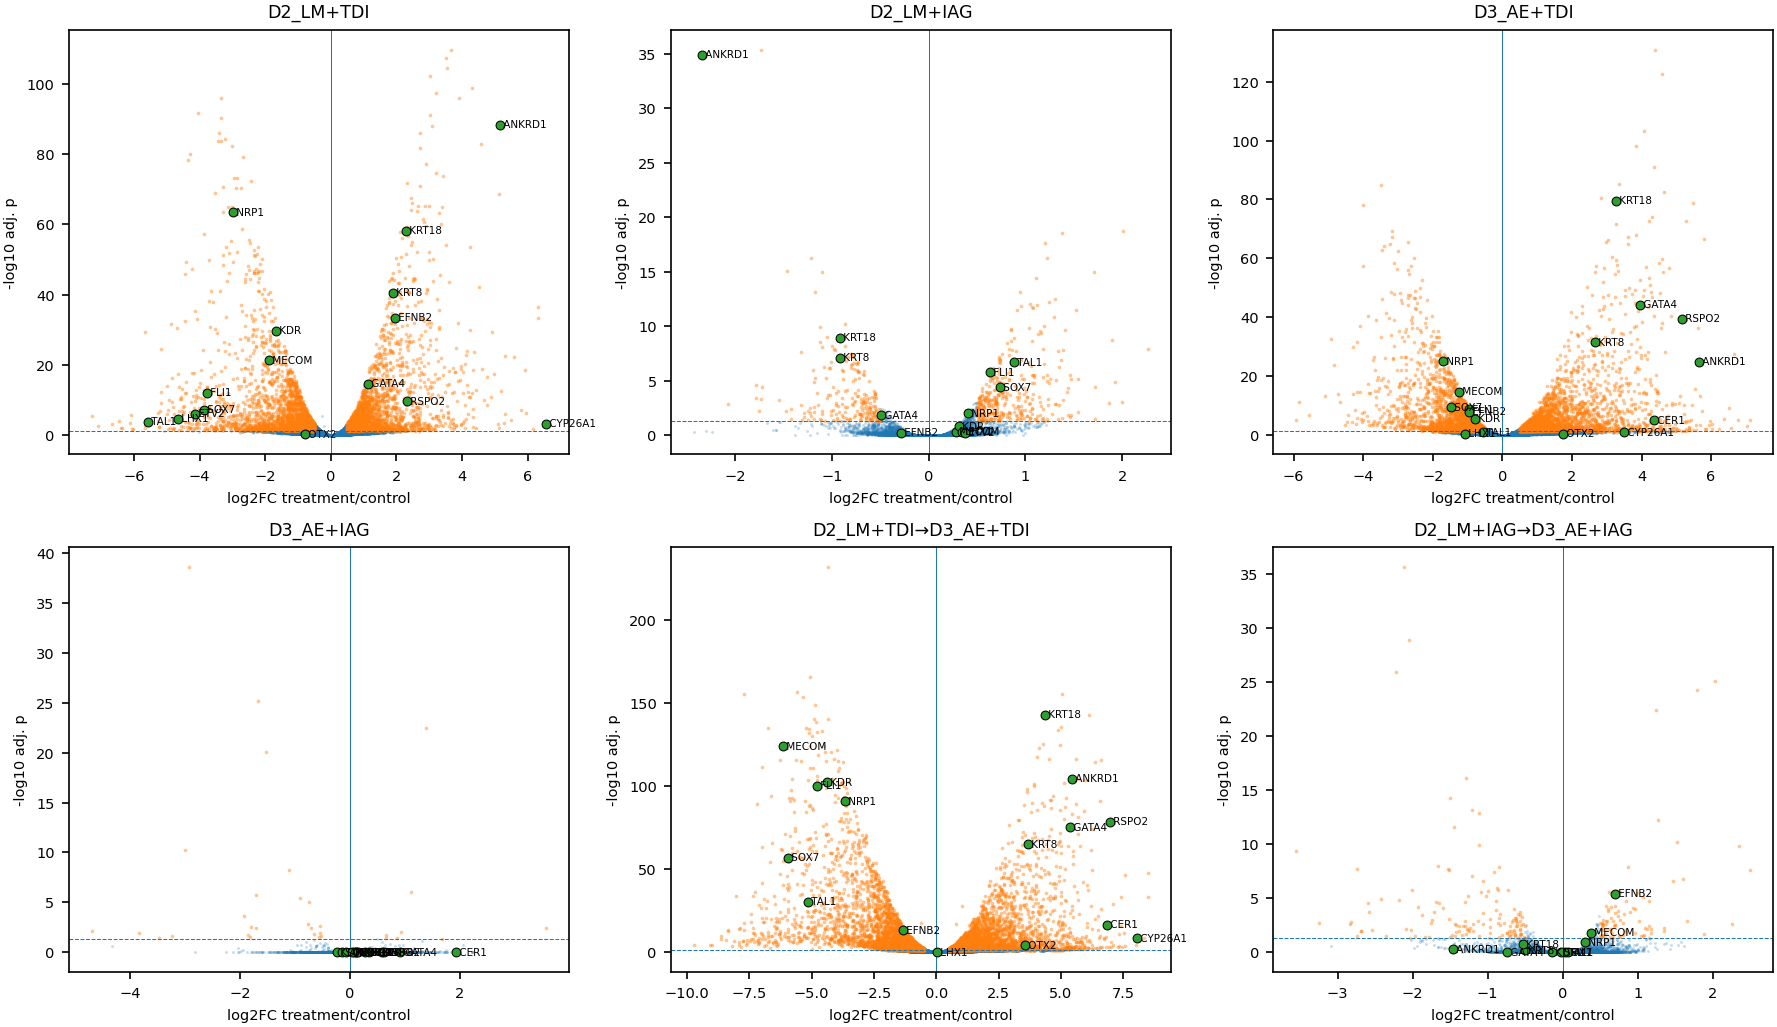

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

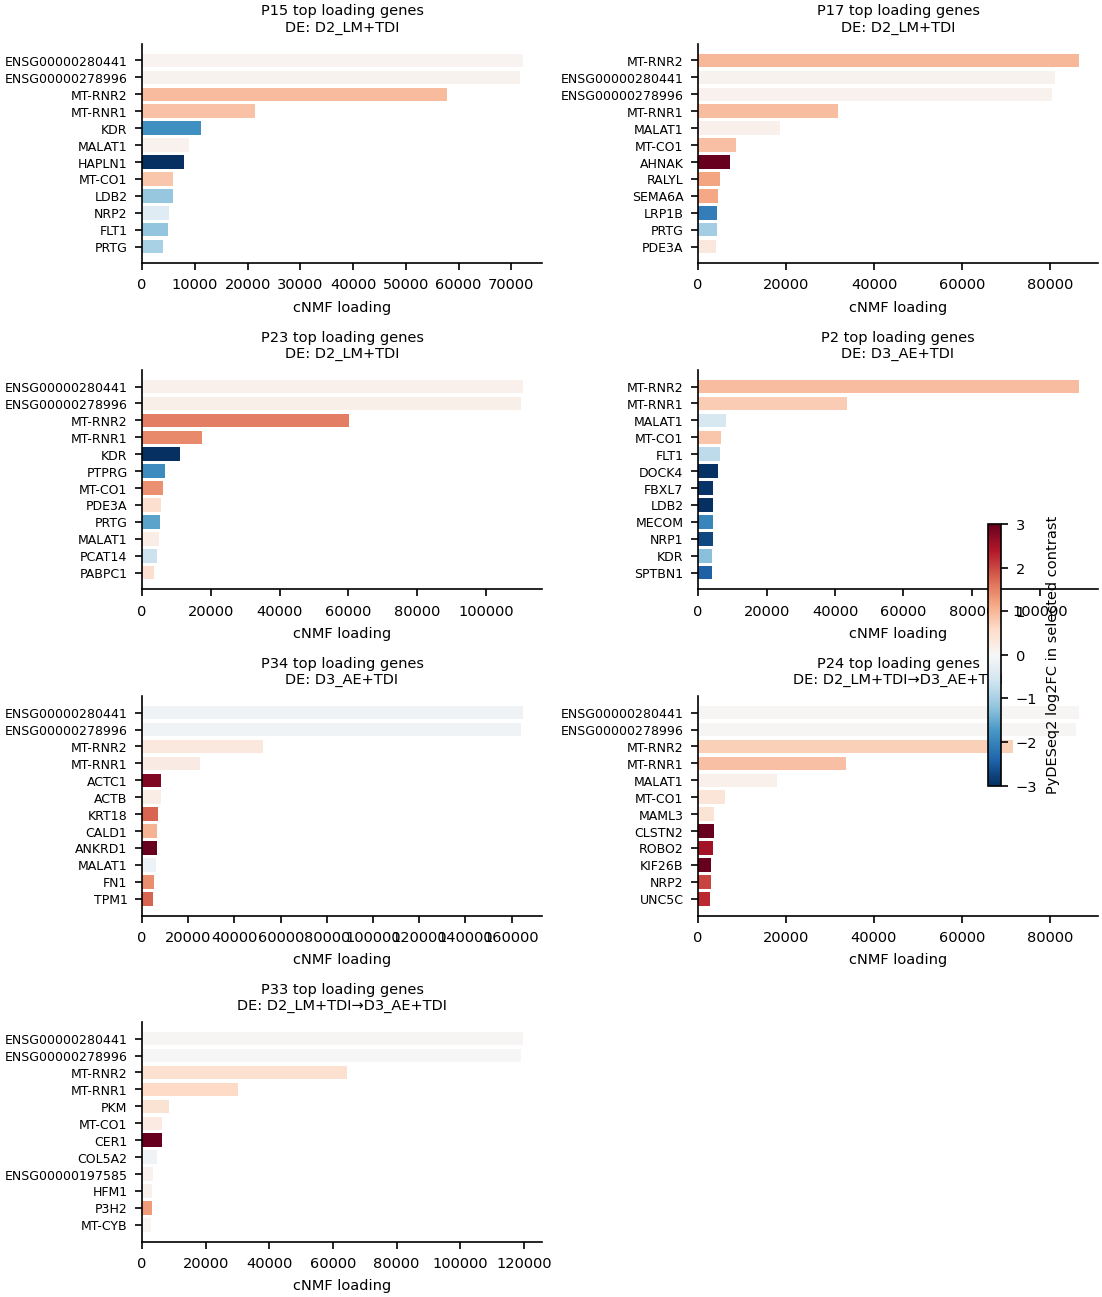

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

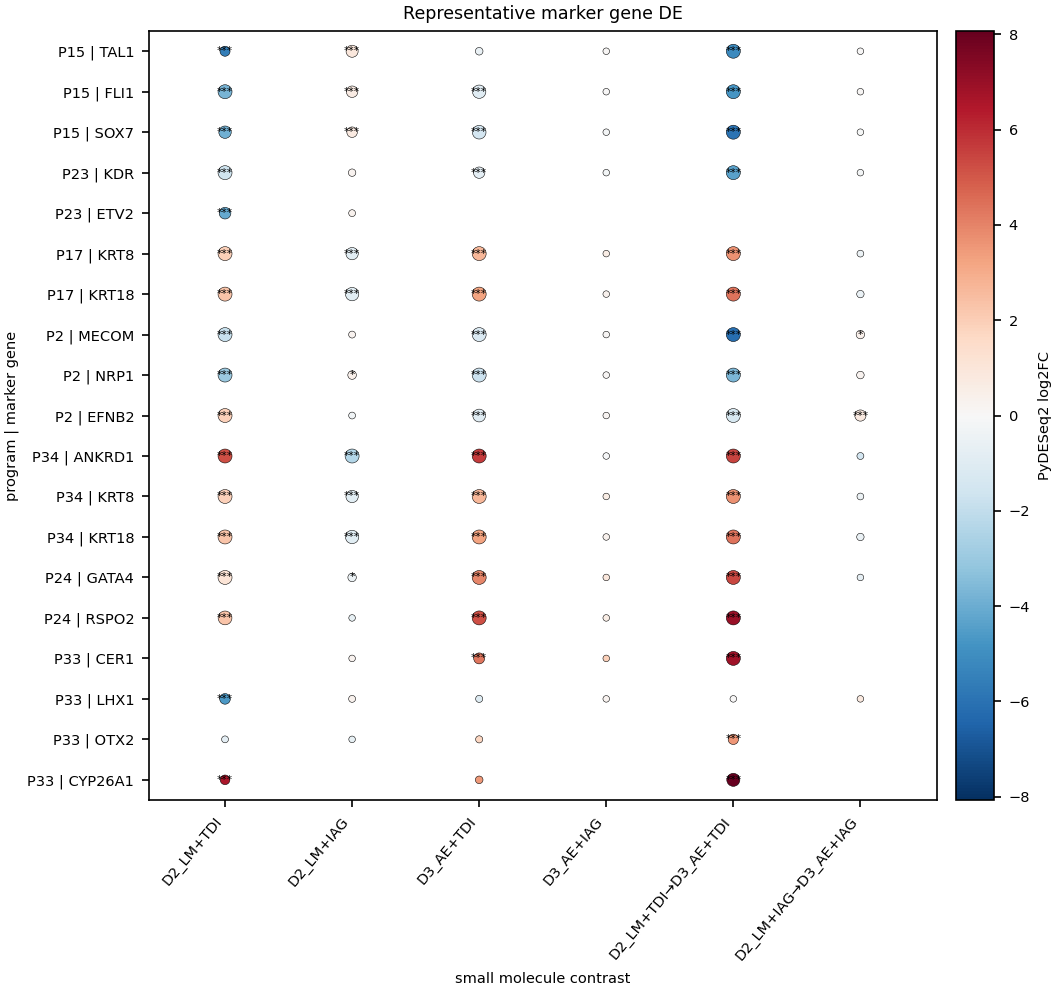

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

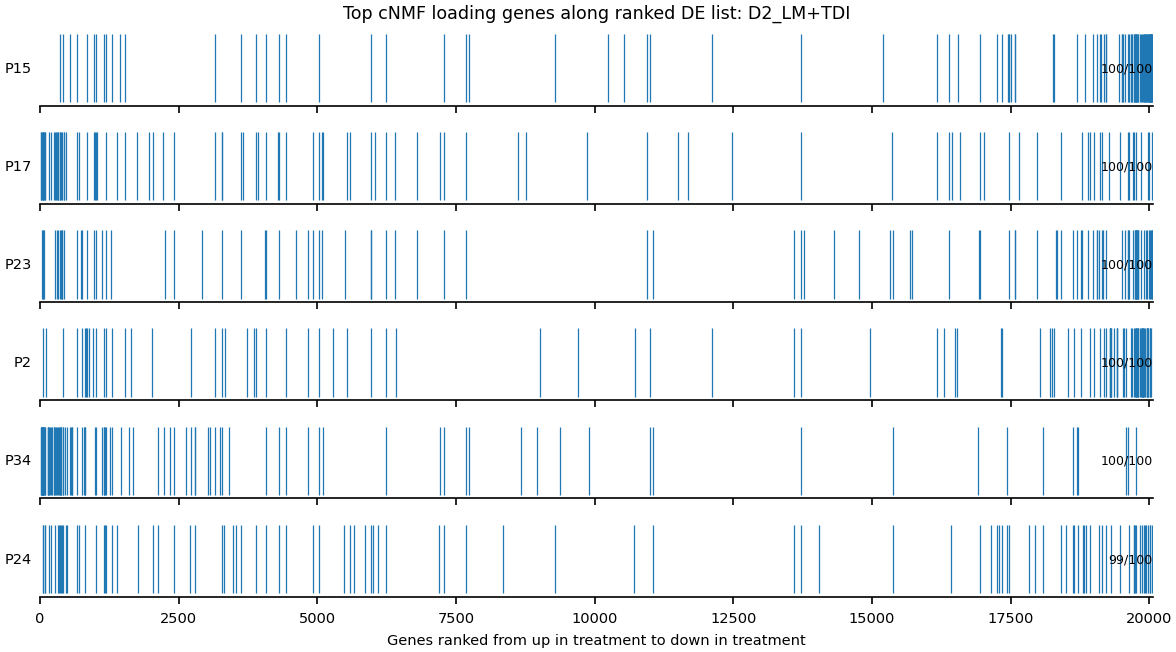

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

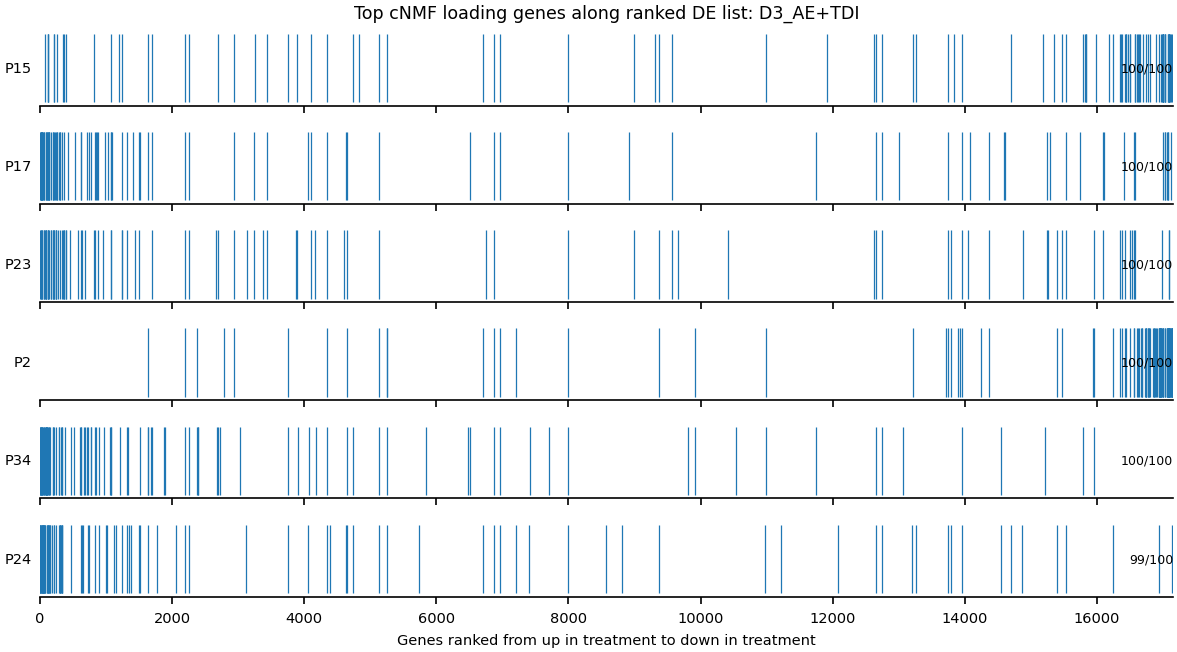

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

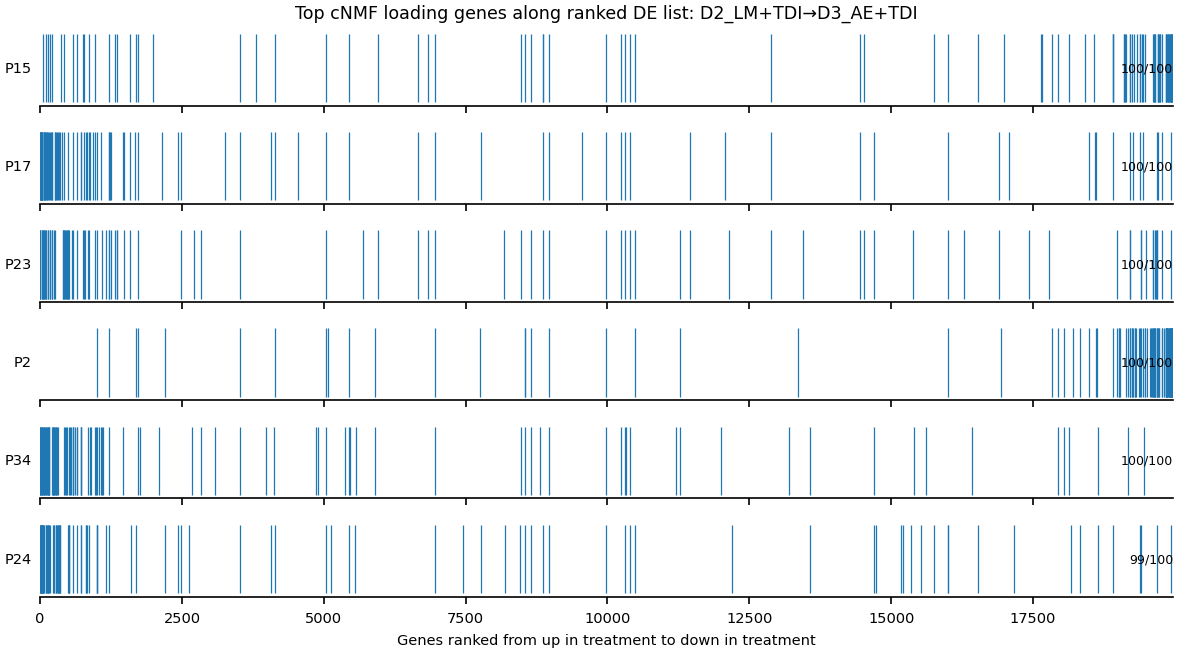

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

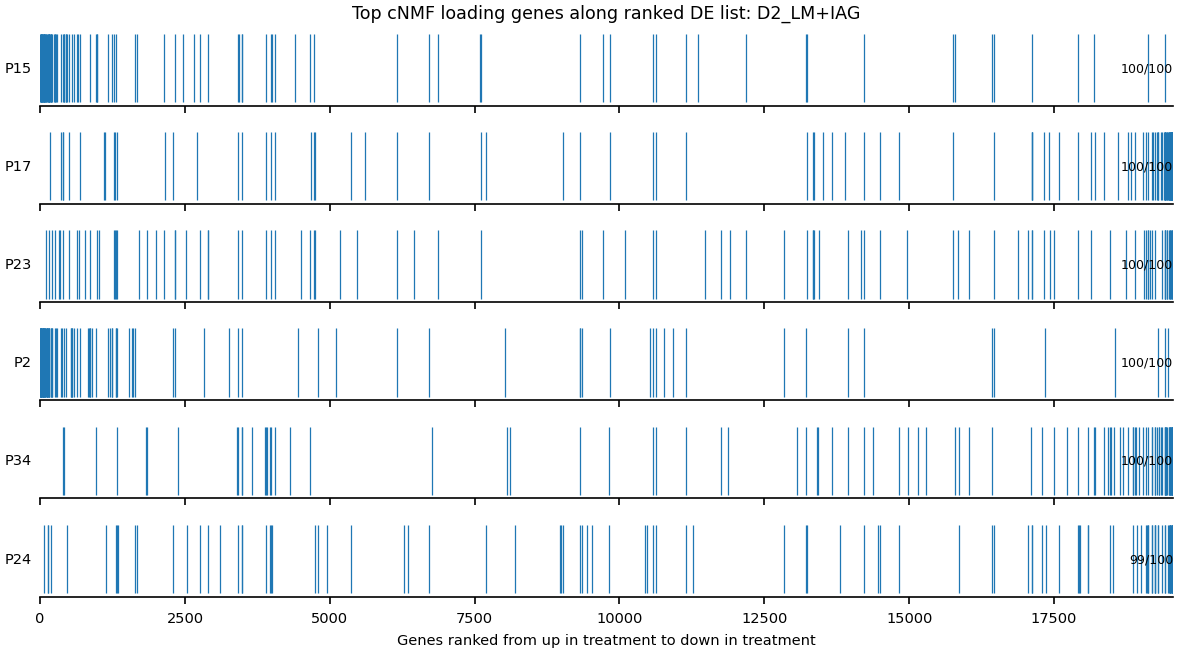

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

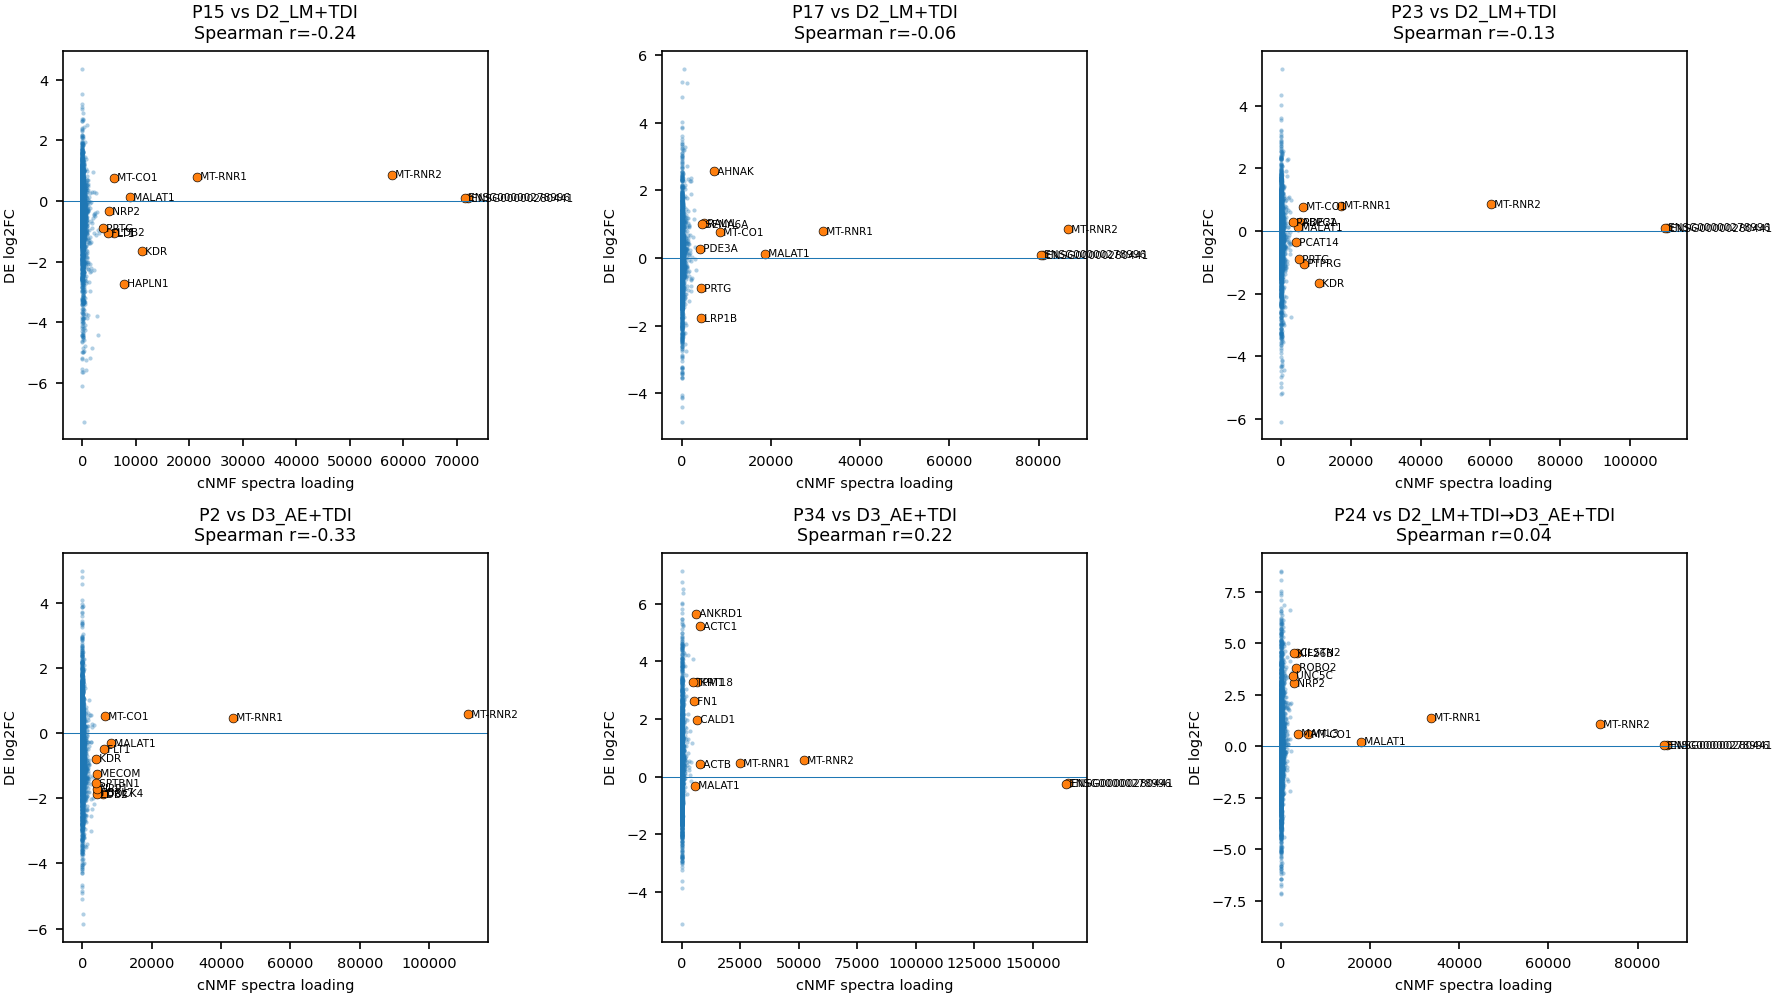

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

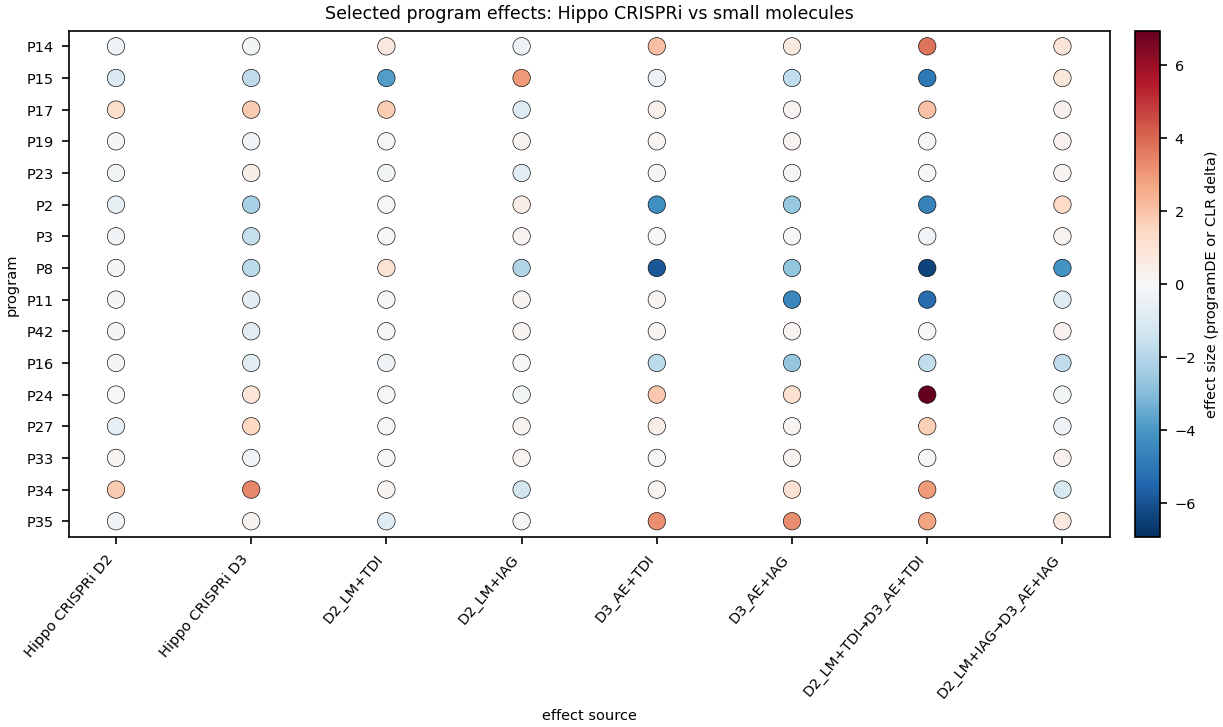

RUN_UMAP_PANELS is False; skipping UMAP panels.
Saved outputs to: /scratch/users/edtng/20260325_Hippo_timecourse/hippo_additional_panels
Panel_barcode_top_loading_genes_D2_LM_IAG.pdf
Panel_barcode_top_loading_genes_D2_LM_IAG.png
Panel_barcode_top_loading_genes_D2_LM_IAG.svg
Panel_barcode_top_loading_genes_D2_LM_TDI.pdf
Panel_barcode_top_loading_genes_D2_LM_TDI.png
Panel_barcode_top_loading_genes_D2_LM_TDI.svg
Panel_barcode_top_loading_genes_D2_LM_TDI_D3_AE_TDI.pdf
Panel_barcode_top_loading_genes_D2_LM_TDI_D3_AE_TDI.png
Panel_barcode_top_loading_genes_D2_LM_TDI_D3_AE_TDI.svg
Panel_barcode_top_loading_genes_D3_AE_TDI.pdf
Panel_barcode_top_loading_genes_D3_AE_TDI.png
Panel_barcode_top_loading_genes_D3_AE_TDI.svg
Panel_loading_vs_DE_scatter_selected_programs.pdf
Panel_loading_vs_DE_scatter_selected_programs.png
Panel_loading_vs_DE_scatter_selected_programs.svg
Panel_loading_vs_DE_scatter_source.tsv
Panel_marker_gene_DE_dotplot.pdf
Panel_marker_gene_DE_dotplot.png
Panel_marker_gene_DE_dotpl

In [6]:
# %% [markdown]
# # Additional Hippo figure panels: volcanoes, top-loading genes, marker-gene DE, and optional UMAPs
#
# This script is designed to run on Sherlock. It uses:
#
# - cNMF workbook: `/scratch/users/edtng/20260325_Hippo_timecourse/cNMF_50_0_2_032526_6co.xlsx`
# - PyDESeq2 contrast tables
# - CLR-matched small-molecule program effects
# - projected zero-based h5ad for optional UMAPs
#
# Outputs are SVG/PDF/PNG with editable text in Illustrator.

# %%
from pathlib import Path
import re
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr, pearsonr

warnings.filterwarnings("ignore")

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 7,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",  # text editable in Illustrator
})

# %% [markdown]
# ## Settings

# %%
BASE = Path("/scratch/users/edtng/20260325_Hippo_timecourse")
OUT_DIR = BASE / "hippo_additional_panels"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CNMF_WORKBOOK_PATH = BASE / "cNMF_50_0_2_032526_6co.xlsx"

SPECTRA_TPM_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50."
    "gene_spectra_tpm.k_50.dt_0_2.txt"
)

DE_DIR = BASE / "perturbseq_cNMF_matched_DE" / "pydeseq2_gene_DE"
CLR_EFFECT_PATH = BASE / "perturbseq_cNMF_matched_DE" / "program_score_DE_clr" / "small_molecule_projected_cNMF_CLR_matched_effects.tsv"
H5AD_PATH = BASE / "perturbseq_cNMF_projection" / "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"

# Optional cell-level UMAP panels. Set True only if H5AD_PATH has X_umap and you want UMAPs.
RUN_UMAP_PANELS = False
UMAP_MAX_CELLS_PER_CONDITION = 8000

# Selected programs from current Hippo model.
D2_PROGRAMS = ["P14", "P15", "P17", "P19", "P23"]
D3_EC_PROGRAMS = ["P2", "P3", "P8", "P11", "P42"]
D3_ALT_PROGRAMS = ["P16", "P24", "P27", "P33", "P34", "P35"]
SELECTED_PROGRAMS = D2_PROGRAMS + D3_EC_PROGRAMS + D3_ALT_PROGRAMS
KEY_PROGRAMS = ["P15", "P17", "P23", "P2", "P34", "P24", "P33"]

# Curated representative marker genes from annotation notes.
PROGRAM_MARKERS = {
    "P15": ["TAL1", "FLI1", "SOX7"],
    "P23": ["KDR", "ETV2"],
    "P17": ["KRT8", "KRT18"],
    "P2": ["MECOM", "NRP1", "EFNB2"],
    "P34": ["ANKRD1", "KRT8", "KRT18"],
    "P24": ["GATA4", "RSPO2"],
    "P33": ["CER1", "LHX1", "OTX2", "CYP26A1"],
}

# Main contrasts for small molecule DE. Keys are display names.
DE_CONTRAST_FILES = {
    "D2_LM+TDI": "PyDESeq2_TDI_at_D2_LM.tsv",
    "D2_LM+IAG": "PyDESeq2_IAG_at_D2_LM.tsv",
    "D3_AE+TDI": "PyDESeq2_TDI_at_D3_AE.tsv",
    "D3_AE+IAG": "PyDESeq2_IAG_at_D3_AE.tsv",
    "D2_LM+TDI→D3_AE+TDI": "PyDESeq2_TDI_D2_to_D3_vs_D3_AE.tsv",
    "D2_LM+IAG→D3_AE+IAG": "PyDESeq2_IAG_D2_to_D3_vs_D3_AE.tsv",
}

# Contrast to use when coloring top-loading genes for a given program.
PROGRAM_TO_MAIN_DE_CONTRAST = {
    "P15": "D2_LM+TDI",
    "P17": "D2_LM+TDI",
    "P23": "D2_LM+TDI",
    "P2": "D3_AE+TDI",
    "P34": "D3_AE+TDI",
    "P24": "D2_LM+TDI→D3_AE+TDI",
    "P33": "D2_LM+TDI→D3_AE+TDI",
    "P14": "D2_LM+TDI",
    "P19": "D2_LM+TDI",
    "P3": "D3_AE+TDI",
    "P8": "D3_AE+TDI",
    "P11": "D3_AE+TDI",
    "P42": "D3_AE+TDI",
    "P16": "D3_AE+TDI",
    "P27": "D3_AE+TDI",
    "P35": "D3_AE+TDI",
}

print("Output:", OUT_DIR)
print("cNMF workbook:", CNMF_WORKBOOK_PATH, CNMF_WORKBOOK_PATH.exists())
print("DE directory:", DE_DIR, DE_DIR.exists())
print("CLR effects:", CLR_EFFECT_PATH, CLR_EFFECT_PATH.exists())
print("Projected h5ad:", H5AD_PATH, H5AD_PATH.exists())

# %% [markdown]
# ## Helper functions

# %%
def save_figure(fig, prefix: Path):
    prefix.parent.mkdir(parents=True, exist_ok=True)
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(prefix.with_suffix(f".{ext}"), bbox_inches="tight")


def program_to_int(p):
    return int(str(p).replace("P", ""))


def clean_gene_symbol(x):
    return str(x).split(".")[0].strip()


def get_de_gene_col(df):
    for col in ["gene", "Gene", "gene_symbol", "symbol", "gene_name", "response_symbol", "index"]:
        if col in df.columns:
            return col
    # PyDESeq2 often writes gene IDs/symbols as unnamed first column.
    first = df.columns[0]
    if str(first).startswith("Unnamed"):
        return first
    return first


def standardize_de_table(path: Path):
    df = pd.read_csv(path, sep="\t")
    gene_col = get_de_gene_col(df)
    df = df.rename(columns={gene_col: "gene"})
    df["gene"] = df["gene"].astype(str).map(clean_gene_symbol)
    if "log2FoldChange" not in df.columns:
        for c in ["log2FC", "log2_fold_change", "lfc"]:
            if c in df.columns:
                df = df.rename(columns={c: "log2FoldChange"})
                break
    if "padj" not in df.columns:
        for c in ["adj_pval", "qvalue", "FDR"]:
            if c in df.columns:
                df = df.rename(columns={c: "padj"})
                break
    if "pvalue" not in df.columns and "pval" in df.columns:
        df = df.rename(columns={"pval": "pvalue"})
    for c in ["log2FoldChange", "padj", "pvalue", "stat"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df


def load_all_de_tables():
    out = {}
    for name, fname in DE_CONTRAST_FILES.items():
        p = DE_DIR / fname
        if p.exists():
            out[name] = standardize_de_table(p)
        else:
            print(f"Missing DE file for {name}: {p}")
    return out


def load_program_loadings():
    loadings = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name="Program Loadings")
    loadings = loadings.rename(columns={c: str(c).strip() for c in loadings.columns})
    loadings["program"] = "P" + loadings["Program"].astype(int).astype(str)
    loadings["Gene"] = loadings["Gene"].astype(str).map(clean_gene_symbol)
    loadings["Rank"] = pd.to_numeric(loadings["Rank"], errors="coerce")
    return loadings


def load_spectra():
    if not SPECTRA_TPM_PATH.exists():
        print("Spectra file not found; top-loading barplots will use ranks instead of weights.")
        return None
    spectra = pd.read_csv(SPECTRA_TPM_PATH, sep="\t", index_col=0)
    # source rows are 1..50; convert to zero-based P0..P49 if applicable
    row_int = [int(float(x)) for x in spectra.index.astype(str)]
    if row_int == list(range(1, len(row_int) + 1)):
        spectra.index = [f"P{i}" for i in range(len(row_int))]
    else:
        spectra.index = [f"P{i}" for i in row_int]
    spectra.columns = spectra.columns.astype(str).map(clean_gene_symbol)
    spectra = spectra.apply(pd.to_numeric, errors="coerce").fillna(0)
    return spectra


def add_de_to_gene_table(gene_df, de_df):
    if de_df is None:
        gene_df["log2FoldChange"] = np.nan
        gene_df["padj"] = np.nan
        return gene_df
    sub = de_df[["gene", "log2FoldChange", "padj"]].copy()
    return gene_df.merge(sub, on="gene", how="left")


def star_from_padj(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


def signed_neglog10_padj(df):
    padj = df["padj"].clip(lower=1e-300)
    return np.sign(df["log2FoldChange"]) * -np.log10(padj)


de_tables = load_all_de_tables()
program_loadings = load_program_loadings()
spectra = load_spectra()
print("Loaded DE tables:", list(de_tables))
print("Program loadings:", program_loadings.shape)
print("Spectra:", None if spectra is None else spectra.shape)

# %% [markdown]
# ## Panel 1: volcano plots with cNMF marker genes highlighted

# %%
def plot_volcano_grid(de_tables, marker_genes_by_program, contrasts_to_plot=None):
    if contrasts_to_plot is None:
        contrasts_to_plot = list(de_tables.keys())
    contrasts_to_plot = [c for c in contrasts_to_plot if c in de_tables]
    n = len(contrasts_to_plot)
    if n == 0:
        print("No DE tables available for volcano plot.")
        return

    highlight_genes = sorted(set(g for genes in marker_genes_by_program.values() for g in genes))
    highlight_gene_to_programs = {}
    for p, genes in marker_genes_by_program.items():
        for g in genes:
            highlight_gene_to_programs.setdefault(g, []).append(p)

    ncols = 3
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.5 * nrows), squeeze=False)

    for ax, contrast in zip(axes.ravel(), contrasts_to_plot):
        df = de_tables[contrast].copy()
        df = df.dropna(subset=["log2FoldChange", "padj"])
        df["neglog10_padj"] = -np.log10(df["padj"].clip(lower=1e-300))
        sig = (df["padj"] < 0.05) & (df["log2FoldChange"].abs() >= 0.5)

        # background points are rasterized to keep the SVG compact; highlighted genes and text are vector/editable.
        ax.scatter(
            df.loc[~sig, "log2FoldChange"],
            df.loc[~sig, "neglog10_padj"],
            s=2,
            alpha=0.25,
            rasterized=True,
            linewidths=0,
        )
        ax.scatter(
            df.loc[sig, "log2FoldChange"],
            df.loc[sig, "neglog10_padj"],
            s=3,
            alpha=0.45,
            rasterized=True,
            linewidths=0,
        )

        hdf = df[df["gene"].isin(highlight_genes)].copy()
        ax.scatter(
            hdf["log2FoldChange"],
            hdf["neglog10_padj"],
            s=18,
            linewidths=0.5,
            edgecolors="black",
            zorder=5,
        )
        for _, r in hdf.iterrows():
            label = r["gene"]
            programs = "/".join(highlight_gene_to_programs.get(label, []))
            ax.text(
                r["log2FoldChange"],
                r["neglog10_padj"],
                f" {label}",
                fontsize=5,
                va="center",
                zorder=6,
            )

        ax.axvline(0, linewidth=0.5)
        ax.axhline(-np.log10(0.05), linewidth=0.5, linestyle="--")
        ax.set_title(contrast)
        ax.set_xlabel("log2FC treatment/control")
        ax.set_ylabel("-log10 adj. p")

    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.tight_layout()
    save_figure(fig, OUT_DIR / "Panel_volcano_marker_genes_key_contrasts")
    plt.show()

plot_volcano_grid(de_tables, PROGRAM_MARKERS)

# %% [markdown]
# ## Panel 2: top-loading gene barplots, colored by DE log2FC in relevant contrast

# %%
def get_top_loading_table(program, top_n=15):
    if spectra is not None and program in spectra.index:
        s = spectra.loc[program].sort_values(ascending=False).head(top_n)
        df = pd.DataFrame({"gene": s.index, "loading": s.values})
        df["rank"] = np.arange(1, df.shape[0] + 1)
    else:
        sub = program_loadings[program_loadings["program"] == program].sort_values("Rank").head(top_n)
        df = pd.DataFrame({
            "gene": sub["Gene"].to_numpy(),
            "loading": top_n + 1 - np.arange(1, sub.shape[0] + 1),
            "rank": sub["Rank"].to_numpy(),
        })
    return df


def plot_top_loading_gene_bars(programs=KEY_PROGRAMS, top_n=12):
    n = len(programs)
    ncols = 2
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.5, max(3, 2.2 * nrows)), squeeze=False)

    source_tables = []
    for ax, program in zip(axes.ravel(), programs):
        tab = get_top_loading_table(program, top_n=top_n)
        contrast = PROGRAM_TO_MAIN_DE_CONTRAST.get(program)
        de = de_tables.get(contrast)
        tab = add_de_to_gene_table(tab, de)
        tab["program"] = program
        tab["de_contrast"] = contrast
        source_tables.append(tab)

        # Sort so highest loading appears at top.
        plot_tab = tab.iloc[::-1].copy()
        values = plot_tab["loading"].to_numpy()
        colors = plot_tab["log2FoldChange"].to_numpy()
        cmap = plt.get_cmap("RdBu_r")
        if np.isfinite(colors).any():
            vmax = np.nanmax(np.abs(colors))
            norm = mpl.colors.Normalize(vmin=-vmax, vmax=vmax)
            bar_colors = cmap(norm(colors))
        else:
            bar_colors = None

        ax.barh(plot_tab["gene"], values, color=bar_colors)
        ax.set_title(f"{program} top loading genes\nDE: {contrast}", fontsize=7)
        ax.set_xlabel("cNMF loading" if spectra is not None else "rank score")
        ax.tick_params(axis="y", labelsize=6)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    for ax in axes.ravel()[n:]:
        ax.axis("off")

    # shared colorbar for DE log2FC
    sm = mpl.cm.ScalarMappable(cmap=plt.get_cmap("RdBu_r"), norm=mpl.colors.Normalize(vmin=-3, vmax=3))
    cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), fraction=0.015, pad=0.02)
    cbar.set_label("PyDESeq2 log2FC in selected contrast")

    fig.tight_layout()
    save_figure(fig, OUT_DIR / "Panel_top_loading_gene_bars_colored_by_DE")
    plt.show()

    src = pd.concat(source_tables, ignore_index=True)
    src.to_csv(OUT_DIR / "Panel_top_loading_gene_bars_source.tsv", sep="\t", index=False)

plot_top_loading_gene_bars(KEY_PROGRAMS, top_n=12)

# %% [markdown]
# ## Panel 3: marker-gene DE dot plot
#
# Rows are curated representative marker genes, columns are treatment contrasts.
# Color is PyDESeq2 log2FC; dot size is -log10 adjusted p-value.

# %%
def build_marker_gene_de_matrix():
    rows = []
    for program, genes in PROGRAM_MARKERS.items():
        for gene in genes:
            rows.append({"program": program, "gene": gene})
    marker_df = pd.DataFrame(rows).drop_duplicates()

    recs = []
    for contrast, de in de_tables.items():
        sub = de[["gene", "log2FoldChange", "padj"]].copy()
        tmp = marker_df.merge(sub, on="gene", how="left")
        tmp["contrast"] = contrast
        recs.append(tmp)
    out = pd.concat(recs, ignore_index=True)
    out["neglog10_padj"] = -np.log10(out["padj"].clip(lower=1e-300))
    out["star"] = out["padj"].map(star_from_padj)
    return out


def plot_marker_gene_de_dotplot():
    df = build_marker_gene_de_matrix()
    df.to_csv(OUT_DIR / "Panel_marker_gene_DE_dotplot_source.tsv", sep="\t", index=False)

    # Define row and column order.
    row_order = []
    for p, genes in PROGRAM_MARKERS.items():
        for g in genes:
            key = f"{p} | {g}"
            if key not in row_order:
                row_order.append(key)
    col_order = list(DE_CONTRAST_FILES.keys())
    col_order = [c for c in col_order if c in df["contrast"].unique()]

    df["row_label"] = df["program"] + " | " + df["gene"]
    df["x"] = df["contrast"].map({c:i for i,c in enumerate(col_order)})
    df["y"] = df["row_label"].map({r:i for i,r in enumerate(row_order)})
    df = df.dropna(subset=["x", "y"])

    fig, ax = plt.subplots(figsize=(max(7, 0.75 * len(col_order) + 3), max(5, 0.25 * len(row_order) + 2)))
    vmax = np.nanmax(np.abs(df["log2FoldChange"])) if np.isfinite(df["log2FoldChange"]).any() else 1
    sizes = 10 + 35 * np.clip(df["neglog10_padj"].fillna(0) / 10, 0, 1)

    sc = ax.scatter(
        df["x"], df["y"],
        c=df["log2FoldChange"],
        s=sizes,
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        edgecolors="black",
        linewidths=0.25,
    )
    for _, r in df.iterrows():
        if r["star"]:
            ax.text(r["x"], r["y"], r["star"], ha="center", va="center", fontsize=5)

    ax.set_xticks(range(len(col_order)))
    ax.set_xticklabels(col_order, rotation=50, ha="right")
    ax.set_yticks(range(len(row_order)))
    ax.set_yticklabels(row_order)
    ax.set_xlim(-0.6, len(col_order) - 0.4)
    ax.set_ylim(len(row_order) - 0.5, -0.5)
    ax.set_title("Representative marker gene DE")
    ax.set_xlabel("small molecule contrast")
    ax.set_ylabel("program | marker gene")
    cbar = fig.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label("PyDESeq2 log2FC")
    fig.tight_layout()
    save_figure(fig, OUT_DIR / "Panel_marker_gene_DE_dotplot")
    plt.show()

plot_marker_gene_de_dotplot()

# %% [markdown]
# ## Panel 4: GSEA-like barcode plots for program top genes on ranked DE lists

# %%
def plot_barcode_for_programs(contrast, programs=("P15", "P17", "P23", "P2", "P34", "P24"), top_n=100):
    if contrast not in de_tables:
        print(f"Missing DE table for {contrast}")
        return
    de = de_tables[contrast].dropna(subset=["log2FoldChange"]).copy()
    if "stat" in de.columns and de["stat"].notna().any():
        de["rank_score"] = de["stat"]
    elif "padj" in de.columns:
        de["rank_score"] = signed_neglog10_padj(de)
    else:
        de["rank_score"] = de["log2FoldChange"]
    de = de.sort_values("rank_score", ascending=False).reset_index(drop=True)
    rank_pos = pd.Series(np.arange(de.shape[0]), index=de["gene"].astype(str)).to_dict()

    n = len(programs)
    fig, axes = plt.subplots(n, 1, figsize=(8.0, max(2.5, 0.75 * n)), sharex=True)
    if n == 1:
        axes = [axes]

    for ax, program in zip(axes, programs):
        top = get_top_loading_table(program, top_n=top_n)["gene"].astype(str).tolist()
        xs = [rank_pos[g] for g in top if g in rank_pos]
        ax.vlines(xs, 0, 1, linewidth=0.6)
        ax.set_yticks([])
        ax.set_ylabel(program, rotation=0, ha="right", va="center")
        ax.set_xlim(0, de.shape[0])
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.text(1.0, 0.5, f"{len(xs)}/{top_n}", transform=ax.transAxes, va="center", ha="right", fontsize=6)

    axes[0].set_title(f"Top cNMF loading genes along ranked DE list: {contrast}")
    axes[-1].set_xlabel("Genes ranked from up in treatment to down in treatment")
    fig.tight_layout()
    safe = re.sub(r"[^A-Za-z0-9_.-]+", "_", contrast)
    save_figure(fig, OUT_DIR / f"Panel_barcode_top_loading_genes_{safe}")
    plt.show()

for c in ["D2_LM+TDI", "D3_AE+TDI", "D2_LM+TDI→D3_AE+TDI", "D2_LM+IAG"]:
    plot_barcode_for_programs(c, programs=["P15", "P17", "P23", "P2", "P34", "P24"], top_n=100)

# %% [markdown]
# ## Panel 5: loading-vs-DE scatter for selected program/contrast pairs

# %%
def plot_loading_vs_de(program_contrast_pairs=None, top_label_n=12):
    if program_contrast_pairs is None:
        program_contrast_pairs = [
            ("P15", "D2_LM+TDI"),
            ("P17", "D2_LM+TDI"),
            ("P23", "D2_LM+TDI"),
            ("P2", "D3_AE+TDI"),
            ("P34", "D3_AE+TDI"),
            ("P24", "D2_LM+TDI→D3_AE+TDI"),
        ]
    n = len(program_contrast_pairs)
    ncols = 3
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.4 * nrows), squeeze=False)

    all_records = []
    for ax, (program, contrast) in zip(axes.ravel(), program_contrast_pairs):
        if spectra is None or program not in spectra.index or contrast not in de_tables:
            ax.axis("off")
            continue
        s = spectra.loc[program]
        tab = pd.DataFrame({"gene": s.index.astype(str), "loading": s.values})
        tab = tab[tab["loading"] > 0]
        de = de_tables[contrast][["gene", "log2FoldChange", "padj"]]
        tab = tab.merge(de, on="gene", how="inner").dropna(subset=["log2FoldChange"])
        if tab.empty:
            ax.axis("off")
            continue

        r_spear, p_spear = spearmanr(tab["loading"], tab["log2FoldChange"])
        ax.scatter(tab["loading"], tab["log2FoldChange"], s=4, alpha=0.35, rasterized=True, linewidths=0)
        top = tab.sort_values("loading", ascending=False).head(top_label_n)
        ax.scatter(top["loading"], top["log2FoldChange"], s=18, edgecolors="black", linewidths=0.3)
        for _, row in top.iterrows():
            ax.text(row["loading"], row["log2FoldChange"], " " + row["gene"], fontsize=5, va="center")
        ax.axhline(0, linewidth=0.5)
        ax.set_title(f"{program} vs {contrast}\nSpearman r={r_spear:.2f}")
        ax.set_xlabel("cNMF spectra loading")
        ax.set_ylabel("DE log2FC")
        tab["program"] = program
        tab["contrast"] = contrast
        tab["spearman_r"] = r_spear
        tab["spearman_p"] = p_spear
        all_records.append(tab)

    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.tight_layout()
    save_figure(fig, OUT_DIR / "Panel_loading_vs_DE_scatter_selected_programs")
    plt.show()
    if all_records:
        pd.concat(all_records, ignore_index=True).to_csv(OUT_DIR / "Panel_loading_vs_DE_scatter_source.tsv", sep="\t", index=False)

plot_loading_vs_de()

# %% [markdown]
# ## Panel 6: small-molecule vs Hippo KD selected program effect dot panel
#
# This complements the scatter/correlation plots by showing the specific selected programs.

# %%
def load_perturbseq_assoc(effect_col="approx_log2FC"):
    assoc = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name="Perturbation Association 1")
    assoc = assoc.copy()
    assoc["program"] = "P" + assoc["program_name"].astype(int).astype(str)
    assoc[effect_col] = pd.to_numeric(assoc[effect_col], errors="coerce")
    return assoc


def plot_selected_program_effect_dotpanel():
    if not CLR_EFFECT_PATH.exists():
        print("CLR effect table missing; skipping selected program effect dotpanel.")
        return
    sm = pd.read_csv(CLR_EFFECT_PATH, sep="\t")
    assoc = load_perturbseq_assoc()
    hippo_targets = ["LATS2", "NF2", "SAV1", "TAOK1", "WWC3", "AMOTL2"]
    hippo = (
        assoc[(assoc["target_name"].isin(hippo_targets)) & (assoc["Sample"].isin(["D2", "D3"])) & (assoc["program"].isin(SELECTED_PROGRAMS))]
        .groupby(["Sample", "program"], observed=True)["approx_log2FC"]
        .mean()
        .reset_index()
    )
    hippo["source"] = "Hippo CRISPRi " + hippo["Sample"].astype(str)
    hippo = hippo.rename(columns={"approx_log2FC": "effect"})

    contrasts_keep = ["D2_LM+TDI", "D2_LM+IAG", "D3_AE+TDI", "D3_AE+IAG", "D2_LM+TDI->D3_AE+TDI", "D2_LM+IAG->D3_AE+IAG"]
    sm = sm[sm["program"].isin(SELECTED_PROGRAMS) & sm["contrast"].isin(contrasts_keep)].copy()
    sm["source"] = sm["contrast"].str.replace("->", "→", regex=False)
    sm = sm.rename(columns={"mean_diff_clr": "effect"})
    plot_df = pd.concat([hippo[["source", "program", "effect"]], sm[["source", "program", "effect"]]], ignore_index=True)

    source_order = ["Hippo CRISPRi D2", "Hippo CRISPRi D3", "D2_LM+TDI", "D2_LM+IAG", "D3_AE+TDI", "D3_AE+IAG", "D2_LM+TDI→D3_AE+TDI", "D2_LM+IAG→D3_AE+IAG"]
    prog_order = SELECTED_PROGRAMS
    plot_df["x"] = plot_df["source"].map({s:i for i,s in enumerate(source_order)})
    plot_df["y"] = plot_df["program"].map({p:i for i,p in enumerate(prog_order)})
    plot_df = plot_df.dropna(subset=["x", "y"])
    vmax = np.nanmax(np.abs(plot_df["effect"]))

    fig, ax = plt.subplots(figsize=(9.0, 5.0))
    sc = ax.scatter(plot_df["x"], plot_df["y"], c=plot_df["effect"], s=70, cmap="RdBu_r", vmin=-vmax, vmax=vmax, edgecolors="black", linewidths=0.3)
    ax.set_xticks(range(len(source_order)))
    ax.set_xticklabels(source_order, rotation=50, ha="right")
    ax.set_yticks(range(len(prog_order)))
    ax.set_yticklabels(prog_order)
    ax.set_ylim(len(prog_order)-0.5, -0.5)
    ax.set_title("Selected program effects: Hippo CRISPRi vs small molecules")
    ax.set_xlabel("effect source")
    ax.set_ylabel("program")
    cbar = fig.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label("effect size (programDE or CLR delta)")
    fig.tight_layout()
    save_figure(fig, OUT_DIR / "Panel_selected_program_effect_dotpanel_HippoCRISPRi_vs_small_molecule")
    plt.show()
    plot_df.to_csv(OUT_DIR / "Panel_selected_program_effect_dotpanel_source.tsv", sep="\t", index=False)

plot_selected_program_effect_dotpanel()

# %% [markdown]
# ## Optional Panel 7: UMAP feature panels for projected programs
#
# This is skipped by default. Set `RUN_UMAP_PANELS = True` at the top if your projected h5ad has `X_umap`.

# %%
def plot_umap_program_panels():
    if not RUN_UMAP_PANELS:
        print("RUN_UMAP_PANELS is False; skipping UMAP panels.")
        return
    import scanpy as sc
    adata = sc.read_h5ad(H5AD_PATH, backed="r")
    if "X_umap" not in adata.obsm:
        print("X_umap not found; skipping UMAP panels.")
        adata.file.close()
        return
    if "X_perturbseq_cNMF_usage" not in adata.obsm:
        print("X_perturbseq_cNMF_usage not found; skipping UMAP panels.")
        adata.file.close()
        return
    obs = adata.obs.copy()
    coords = np.asarray(adata.obsm["X_umap"])
    usage = np.asarray(adata.obsm["X_perturbseq_cNMF_usage"])
    meta = adata.uns.get("perturbseq_cNMF_projection", {})
    program_names = [str(x) for x in meta.get("program_names", [f"P{i}" for i in range(usage.shape[1])])]
    p_to_idx = {p:i for i,p in enumerate(program_names)}
    if "condition" not in obs.columns and "sample_name" in obs.columns:
        obs["condition"] = obs["sample_name"].astype(str).str.replace(r"_rep\d+$", "", regex=True)
    conditions = ["D2_LM", "D2_LM+TDI", "D2_LM+IAG", "D3_AE", "D3_AE+TDI", "D3_AE+IAG", "D2_LM+TDI->D3_AE+TDI", "D2_LM+IAG->D3_AE+IAG"]
    rng = np.random.default_rng(0)
    for program in ["P15", "P17", "P23", "P2", "P34", "P24"]:
        if program not in p_to_idx:
            continue
        fig, axes = plt.subplots(2, 4, figsize=(9, 4.8), squeeze=False)
        vals = usage[:, p_to_idx[program]]
        vmax = np.quantile(vals[vals > 0], 0.99) if np.any(vals > 0) else 1
        for ax, cond in zip(axes.ravel(), conditions):
            idx = np.where(obs["condition"].astype(str).to_numpy() == cond)[0]
            if idx.size > UMAP_MAX_CELLS_PER_CONDITION:
                idx = rng.choice(idx, size=UMAP_MAX_CELLS_PER_CONDITION, replace=False)
            ax.scatter(coords[idx,0], coords[idx,1], c=vals[idx], s=1, cmap="viridis", vmin=0, vmax=vmax, linewidths=0, rasterized=True)
            ax.set_title(cond, fontsize=7)
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_visible(False)
        fig.suptitle(f"Projected {program} usage on UMAP", y=1.02)
        fig.tight_layout()
        save_figure(fig, OUT_DIR / f"Panel_UMAP_projected_{program}_by_condition")
        plt.show()
    adata.file.close()

plot_umap_program_panels()

# %%
print("Saved outputs to:", OUT_DIR)
for p in sorted(OUT_DIR.glob("Panel_*")):
    print(p.name)


#### UMAP

In [8]:
# %% [markdown]
# # Perturb-seq D3 Hippo UMAP panels: alternative states
#
# This notebook/script makes UMAP panels from the perturb-seq dataset itself,
# focused on whether Hippo perturbations occupy D3 alternative/YAP-like states.
#
# Outputs:
# - D3 UMAP colored by selected perturb-seq cNMF programs
# - D3 UMAP colored by EC score, alternative/YAP score, and alternative-minus-EC score
# - D3 UMAP highlighting Hippo KD carrier cells vs controls/other cells
# - D3 UMAP panels for individual Hippo KD targets
# - D3 target-level summary dot/bar plots for selected programs and EC/alternative scores
#
# Edit the USER SETTINGS cell if your day/target columns differ.

# %%
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import scanpy as sc
import muon as mu
from scipy import sparse

warnings.filterwarnings("ignore")

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 7,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",  # keep text editable in Illustrator
})

# %% [markdown]
# ## User settings

# %%
# Perturb-seq cNMF h5mu from the perturb-seq screen.
H5MU_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/adata/cNMF_50_0_2.h5mu"
)

# Integrated perturb-seq h5ad used previously for UMAP and obs metadata.
# If your cNMF h5mu already has X_umap and target metadata, you can set USE_INTEGRATED_H5AD_FOR_UMAP_AND_OBS = False.
USE_INTEGRATED_H5AD_FOR_UMAP_AND_OBS = True
ADATA_INT_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/"
    "2.preprocessing_tonys_pipeline/3.integrated_days/"
    "3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad"
)

OUT_DIR = Path("/scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_hippo_d3_umap_alt_state_panels")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# If set to None, the script tries to infer columns and prints candidates.
DAY_COL = "day"  # use the real day column; do not infer from well values
TARGET_COL = None

# D3 values are detected by string contains "D3" by default.
D3_VALUE_REGEX = r"D3"

# Hippo KD targets to highlight.
HIPPO_TARGETS = ["LATS2", "NF2", "SAV1", "TAOK1", "WWC3", "AMOTL2"]

# Control labels, if TARGET_COL has a target/perturbation label.
CONTROL_REGEX = r"NT|NON[-_ ]?TARGET|CONTROL|SAFE|SCRAMBLE|INTERGENIC|NEG"

# If no target column exists in obs, derive target labels from guide assignments.
# The integrated h5ad usually stores guide names in uns["guide_names"] and guide calls in obsm["guide_assignment"].
GUIDE_NAMES_KEY = "guide_names"
GUIDE_ASSIGNMENT_KEY = "guide_assignment"
GUIDE_METADATA_TSV_CANDIDATES = [
    Path("300genes_guide_metadata_v43.tsv"),
    Path("/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/d3_EC_percent_by_target_biorep/300genes_guide_metadata_v43.tsv"),
    Path("/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/300genes_guide_metadata_v43.tsv"),
    Path("/scratch/users/edtng/20260325_Hippo_timecourse/300genes_guide_metadata_v43.tsv"),
]
GUIDE_ID_COL = "guide_id"
GUIDE_TARGET_COL_CANDIDATES = [
    "putative_target_genes",
    "intended_target_name",
    "target_name",
    "target",
    "gene",
]
CONTROL_TARGET_NAME = "non-targeting_control"

# Selected programs. These are zero-based perturb-seq cNMF program IDs.
D2_BRANCH_PROGRAMS = ["P14", "P15", "P17", "P19", "P23"]
D3_EC_PROGRAMS = ["P2", "P3", "P8", "P11", "P42"]
D3_ALT_PROGRAMS = ["P16", "P24", "P27", "P33", "P34", "P35"]
KEY_PROGRAMS_TO_UMAP = ["P15", "P17", "P23", "P2", "P34", "P24"]

# Use normalized program scores for UMAP features. If False, uses raw cnmf.X.
ROW_NORMALIZE_CNMFSCORES = True

# UMAP plotting options.
POINT_SIZE_ALL = 0.15
POINT_SIZE_HIGHLIGHT = 0.8
UMAP_ALPHA_ALL = 0.65
UMAP_ALPHA_HIGHLIGHT = 0.95
RASTERIZE_POINTS = True  # keeps SVG compact; text remains editable
MAX_CELLS_FOR_CONTINUOUS_UMAP = None  # set e.g. 120000 for faster plotting; None = all D3 cells
RANDOM_SEED = 0

# Color limits for continuous UMAPs.
FEATURE_VMIN_QUANTILE = 0.00
FEATURE_VMAX_QUANTILE = 0.995

# %% [markdown]
# ## Helper functions

# %%
def to_dense_array(x):
    if sparse.issparse(x):
        return x.toarray()
    return np.asarray(x)


def sanitize_name(x):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(x)).strip("_")


def parse_program_id(program):
    return int(str(program).replace("P", ""))


def infer_day_column(obs):
    # Prefer explicit day columns by name. The old heuristic can mistake well values like D10 for day labels.
    for preferred in ["day", "diff_day", "biological_sample"]:
        if preferred in obs.columns:
            return [(preferred, obs[preferred].nunique(dropna=False), 999, 999, obs[preferred].astype(str).dropna().unique()[:10].tolist())]
    candidates = []
    for col in obs.columns:
        s = obs[col].astype(str)
        vals = s.dropna().unique()
        if len(vals) > 200:
            continue
        d_hits = sum(bool(re.search(r"D[0-9]", v, flags=re.IGNORECASE)) for v in vals)
        day_hits = sum("day" in v.lower() for v in vals)
        if d_hits > 0 or day_hits > 0:
            candidates.append((col, len(vals), d_hits, day_hits, list(vals[:10])))
    return candidates


def infer_target_column(obs, hippo_targets):
    hippo = [t.upper() for t in hippo_targets]
    candidates = []
    for col in obs.columns:
        if obs[col].dtype.name not in ["category", "object", "string"]:
            continue
        s = obs[col].astype(str).str.upper()
        vals = s.dropna().unique()
        if len(vals) > 2000:
            # target columns should not usually have one unique value per cell.
            continue
        n_hippo = int(sum(s.str.contains("|".join(hippo), regex=True, na=False)))
        n_control = int(sum(s.str.contains(CONTROL_REGEX, regex=True, na=False)))
        if n_hippo > 0 or n_control > 0:
            candidates.append((col, len(vals), n_hippo, n_control, list(vals[:10])))
    candidates = sorted(candidates, key=lambda x: (x[2], x[3]), reverse=True)
    return candidates


def looks_control(x):
    s = str(x).lower()
    return bool(re.search(CONTROL_REGEX, s, flags=re.IGNORECASE))


def clean_target_entry(x):
    if pd.isna(x):
        return []
    s = str(x).strip()
    if s.lower() in ["", "nan", "none", "na"]:
        return []
    s = s.replace("[", "").replace("]", "").replace("'", "").replace('"', "")
    parts = re.split(r"[;,|/]+", s)
    return [p.strip() for p in parts if p.strip()]


def canonical_guide_id(x):
    return str(x).strip().replace(" ", "")


def find_guide_metadata_tsv():
    for p in GUIDE_METADATA_TSV_CANDIDATES:
        if p.exists():
            return p
    raise FileNotFoundError(
        "Could not find guide metadata TSV. Put 300genes_guide_metadata_v43.tsv in the working directory "
        "or add its path to GUIDE_METADATA_TSV_CANDIDATES. Tried:\n"
        + "\n".join(str(p) for p in GUIDE_METADATA_TSV_CANDIDATES)
    )


def infer_target_col_from_metadata(meta):
    for col in GUIDE_TARGET_COL_CANDIDATES:
        if col in meta.columns:
            return col
    raise ValueError(
        "Could not find a target column in guide metadata. "
        f"Available columns: {meta.columns.tolist()}"
    )


def get_guide_assignment_matrix(adata):
    ga = adata.obsm[GUIDE_ASSIGNMENT_KEY]
    if sparse.issparse(ga):
        return ga.tocsr().astype(bool)
    return np.asarray(ga).astype(bool)


def build_guide_index_to_targets(adata):
    if GUIDE_NAMES_KEY not in adata.uns:
        raise KeyError(f"adata.uns is missing {GUIDE_NAMES_KEY!r}")
    if GUIDE_ASSIGNMENT_KEY not in adata.obsm:
        raise KeyError(f"adata.obsm is missing {GUIDE_ASSIGNMENT_KEY!r}")

    guide_names = list(map(str, adata.uns[GUIDE_NAMES_KEY]))
    guide_name_to_idx = {g: i for i, g in enumerate(guide_names)}

    meta_path = find_guide_metadata_tsv()
    print("Using guide metadata TSV:", meta_path)
    meta = pd.read_csv(meta_path, sep="\t")

    if GUIDE_ID_COL not in meta.columns:
        raise ValueError(f"{GUIDE_ID_COL!r} not found in guide metadata. Columns: {meta.columns.tolist()}")
    target_col = infer_target_col_from_metadata(meta)

    meta = meta.copy()
    meta[GUIDE_ID_COL] = meta[GUIDE_ID_COL].astype(str)
    meta["raw_target_entry"] = meta[target_col]

    # exact match
    meta["guide_index"] = meta[GUIDE_ID_COL].map(guide_name_to_idx)
    meta["match_method"] = np.where(meta["guide_index"].notna(), "exact", None)

    # fallback canonical guide-id match
    if meta["guide_index"].isna().any():
        canonical_to_guide = {}
        duplicated = set()
        for g in guide_names:
            cg = canonical_guide_id(g)
            if cg in canonical_to_guide:
                duplicated.add(cg)
            else:
                canonical_to_guide[cg] = g
        for cg in duplicated:
            canonical_to_guide.pop(cg, None)

        for idx in meta.index[meta["guide_index"].isna()]:
            cg = canonical_guide_id(meta.at[idx, GUIDE_ID_COL])
            if cg in canonical_to_guide:
                matched = canonical_to_guide[cg]
                meta.at[idx, "guide_index"] = guide_name_to_idx[matched]
                meta.at[idx, "match_method"] = "canonical"

    mapped = meta[meta["guide_index"].notna()].copy()
    mapped["guide_index"] = mapped["guide_index"].astype(int)
    mapped["guide_name"] = mapped["guide_index"].map(lambda i: guide_names[i])

    guide_index_to_targets = {}
    records = []
    for _, row in mapped.iterrows():
        guide_index = int(row["guide_index"])
        guide_name = str(row["guide_name"])
        raw_target = row["raw_target_entry"]

        if looks_control(row[GUIDE_ID_COL]) or looks_control(guide_name) or looks_control(raw_target):
            targets = [CONTROL_TARGET_NAME]
        else:
            targets = clean_target_entry(raw_target)

        guide_index_to_targets.setdefault(guide_index, [])
        for target in targets:
            target = str(target)
            guide_index_to_targets[guide_index].append(target)
            records.append({
                "guide_index": guide_index,
                "guide_name": guide_name,
                "target_name": target,
                "raw_target_entry": raw_target,
                "match_method": row["match_method"],
            })

    guide_target_df = pd.DataFrame(records).drop_duplicates()
    guide_target_df.to_csv(OUT_DIR / "guide_to_target_mapping_used_for_umap.tsv", sep="\t", index=False)

    print("Guide metadata mapping QC")
    print(f"  adata guide columns: {len(guide_names):,}")
    print(f"  metadata rows: {len(meta):,}")
    print(f"  mapped guide rows: {mapped[GUIDE_ID_COL].nunique():,}")
    print(f"  expanded guide-target rows: {len(guide_target_df):,}")
    if len(guide_target_df) > 0:
        print("  top targets:")
        print(guide_target_df["target_name"].value_counts().head(15).to_string())

    return guide_index_to_targets


def target_series_from_guide_assignment(adata, row_positions, index):
    guide_index_to_targets = build_guide_index_to_targets(adata)
    guide_assignment = get_guide_assignment_matrix(adata)

    if row_positions is not None:
        guide_assignment = guide_assignment[row_positions, :]

    target_strings = []
    n_with_any_target = 0
    for i in range(guide_assignment.shape[0]):
        if sparse.issparse(guide_assignment):
            guide_idx = guide_assignment[i].indices
        else:
            guide_idx = np.flatnonzero(guide_assignment[i])

        targets = []
        for gidx in guide_idx:
            targets.extend(guide_index_to_targets.get(int(gidx), []))

        # keep unique targets but preserve order
        targets = list(dict.fromkeys([str(t) for t in targets if str(t)]))
        if targets:
            n_with_any_target += 1
            target_strings.append(";".join(targets))
        else:
            target_strings.append("unassigned")

    print(f"Cells with at least one mapped guide target: {n_with_any_target:,} / {len(target_strings):,}")
    return pd.Series(target_strings, index=index, dtype=object), "derived_from_guide_assignment"


def get_target_series(obs, target_col, hippo_targets, adata_for_guides=None, row_positions=None):
    if target_col is not None:
        return obs[target_col].astype(str), target_col

    candidates = infer_target_column(obs, hippo_targets)
    print("Candidate target columns:")
    for c in candidates[:20]:
        print(c)
    if candidates:
        target_col = candidates[0][0]
        print(f"Using inferred TARGET_COL={target_col!r}")
        return obs[target_col].astype(str), target_col

    print("No target-like obs column found. Trying to derive target labels from guide_assignment + guide metadata...")
    if adata_for_guides is not None:
        return target_series_from_guide_assignment(adata_for_guides, row_positions, obs.index)

    raise ValueError(
        "Could not infer target column and no adata_for_guides was provided. "
        "Set TARGET_COL manually or provide guide_assignment/guide_names."
    )


def get_day_series(obs, day_col):
    if day_col is None:
        candidates = infer_day_column(obs)
        print("Candidate day columns:")
        for c in candidates[:20]:
            print(c)
        if not candidates:
            raise ValueError("Could not infer day column. Set DAY_COL manually after inspecting obs columns.")
        day_col = candidates[0][0]
        print(f"Using inferred DAY_COL={day_col!r}")
    return obs[day_col].astype(str), day_col


def make_target_group(target_string_series):
    s = target_string_series.astype(str).str.upper()
    hippo_regex = "|".join([re.escape(t.upper()) for t in HIPPO_TARGETS])
    out = pd.Series("Other", index=target_string_series.index, dtype=object)
    out[s.str.contains(CONTROL_REGEX, regex=True, na=False)] = "Control/NT"
    out[s.str.contains(hippo_regex, regex=True, na=False)] = "Hippo KD"
    return out


def get_individual_hippo_target(target_string):
    s = str(target_string).upper()
    hits = [t for t in HIPPO_TARGETS if re.search(rf"\b{re.escape(t.upper())}\b", s)]
    if hits:
        return hits[0]
    # fallback substring match for combined guide strings
    hits = [t for t in HIPPO_TARGETS if t.upper() in s]
    return hits[0] if hits else None


def robust_feature_limits(values, qmin=0.0, qmax=0.995):
    finite = values[np.isfinite(values)]
    if finite.size == 0:
        return 0, 1
    vmin = float(np.quantile(finite, qmin))
    vmax = float(np.quantile(finite, qmax))
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-9
    return vmin, vmax


def plot_umap_continuous(df, value_col, title, out_prefix, cmap="viridis", overlay_hippo=True):
    plot_df = df.copy()
    if MAX_CELLS_FOR_CONTINUOUS_UMAP is not None and len(plot_df) > MAX_CELLS_FOR_CONTINUOUS_UMAP:
        plot_df = plot_df.sample(MAX_CELLS_FOR_CONTINUOUS_UMAP, random_state=RANDOM_SEED)

    vals = plot_df[value_col].to_numpy(dtype=float)
    vmin, vmax = robust_feature_limits(vals, FEATURE_VMIN_QUANTILE, FEATURE_VMAX_QUANTILE)
    order = np.argsort(vals)
    plot_df = plot_df.iloc[order]

    fig, ax = plt.subplots(figsize=(4.5, 4.2))
    sca = ax.scatter(
        plot_df["UMAP1"], plot_df["UMAP2"],
        c=plot_df[value_col],
        s=POINT_SIZE_ALL,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        alpha=UMAP_ALPHA_ALL,
        linewidths=0,
        rasterized=RASTERIZE_POINTS,
    )

    if overlay_hippo and "target_group" in plot_df.columns:
        hippo = plot_df[plot_df["target_group"] == "Hippo KD"]
        if len(hippo) > 0:
            ax.scatter(
                hippo["UMAP1"], hippo["UMAP2"],
                facecolors="none",
                edgecolors="black",
                s=POINT_SIZE_HIGHLIGHT * 3,
                linewidths=0.25,
                alpha=0.5,
                rasterized=RASTERIZE_POINTS,
            )

    ax.set_title(title)
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_visible(False)
    cb = fig.colorbar(sca, ax=ax, fraction=0.046, pad=0.02)
    cb.set_label(value_col)
    fig.tight_layout()
    for ext in ["png", "pdf", "svg"]:
        fig.savefig(OUT_DIR / f"{out_prefix}.{ext}", bbox_inches="tight")
    plt.close(fig)


def plot_umap_target_groups(df, title, out_prefix):
    fig, ax = plt.subplots(figsize=(4.5, 4.2))
    # Use neutral/standard colors. Edit if needed for journal palette.
    group_order = ["Other", "Control/NT", "Hippo KD"]
    colors = {"Other": "#d9d9d9", "Control/NT": "#4d4d4d", "Hippo KD": "#d62728"}
    sizes = {"Other": 0.10, "Control/NT": 0.20, "Hippo KD": 0.80}
    alphas = {"Other": 0.25, "Control/NT": 0.55, "Hippo KD": 0.9}
    zorders = {"Other": 1, "Control/NT": 2, "Hippo KD": 3}

    for group in group_order:
        sub = df[df["target_group"] == group]
        if len(sub) == 0:
            continue
        ax.scatter(
            sub["UMAP1"], sub["UMAP2"],
            c=colors[group],
            s=sizes[group],
            alpha=alphas[group],
            linewidths=0,
            label=f"{group} (n={len(sub):,})",
            rasterized=RASTERIZE_POINTS,
            zorder=zorders[group],
        )

    ax.legend(frameon=False, loc="upper right", fontsize=6, markerscale=4)
    ax.set_title(title)
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.tight_layout()
    for ext in ["png", "pdf", "svg"]:
        fig.savefig(OUT_DIR / f"{out_prefix}.{ext}", bbox_inches="tight")
    plt.close(fig)

# %% [markdown]
# ## Load cNMF scores, UMAP, obs metadata, and align cells

# %%
print("Loading cNMF h5mu:", H5MU_PATH)
mdata = mu.read_h5mu(H5MU_PATH)
cnmf = mdata.mod["cNMF"]
cnmf_cells = pd.Index(cnmf.obs_names.astype(str))

scores = to_dense_array(cnmf.X).astype(np.float32)
if ROW_NORMALIZE_CNMFSCORES:
    row_sums = scores.sum(axis=1, keepdims=True)
    scores = np.divide(scores, row_sums, out=np.zeros_like(scores), where=row_sums > 0)

program_names = [f"P{i}" for i in range(scores.shape[1])]
score_df = pd.DataFrame(scores, index=cnmf_cells, columns=program_names)
print("cNMF score matrix:", score_df.shape)

ADATA_FOR_GUIDES = None
ROW_POSITIONS_FOR_GUIDES = None

if USE_INTEGRATED_H5AD_FOR_UMAP_AND_OBS:
    print("Loading integrated h5ad for UMAP/obs:", ADATA_INT_PATH)
    adata_int = sc.read_h5ad(ADATA_INT_PATH, backed="r")
    print("integrated h5ad obsm keys:", list(adata_int.obsm.keys()))
    print("integrated h5ad uns keys first 30:", list(adata_int.uns.keys())[:30])
    source_cells = pd.Index(adata_int.obs_names.astype(str))
    if not cnmf_cells.isin(source_cells).all():
        missing = cnmf_cells[~cnmf_cells.isin(source_cells)][:10].tolist()
        raise ValueError(f"Some cNMF cells are missing from integrated h5ad. Examples: {missing}")
    pos = source_cells.get_indexer(cnmf_cells)
    obs = adata_int.obs.iloc[pos].copy()
    if "X_umap" not in adata_int.obsm:
        raise KeyError(f"X_umap not found in ADATA_INT. obsm keys: {list(adata_int.obsm.keys())}")
    umap = np.asarray(adata_int.obsm["X_umap"])[pos, :2]
    ADATA_FOR_GUIDES = adata_int
    ROW_POSITIONS_FOR_GUIDES = pos
else:
    obs = cnmf.obs.copy()
    if "X_umap" not in cnmf.obsm:
        raise KeyError("X_umap not found in cnmf.obsm. Set USE_INTEGRATED_H5AD_FOR_UMAP_AND_OBS=True.")
    umap = np.asarray(cnmf.obsm["X_umap"])

obs.index = cnmf_cells
umap_df = pd.DataFrame(umap, index=cnmf_cells, columns=["UMAP1", "UMAP2"])

print("obs shape:", obs.shape)
print("UMAP shape:", umap_df.shape)
print("obs columns:")
print(list(obs.columns))

# %% [markdown]
# ## Identify D3 cells and Hippo target groups

# %%
day_series, DAY_COL_USED = get_day_series(obs, DAY_COL)
d3_mask = day_series.str.contains(D3_VALUE_REGEX, regex=True, case=False, na=False)
print("DAY_COL_USED:", DAY_COL_USED)
print("D3 cells:", int(d3_mask.sum()), "of", len(d3_mask))
print("Day value counts:")
print(day_series.value_counts(dropna=False).head(20))

target_series, TARGET_COL_USED = get_target_series(
    obs,
    TARGET_COL,
    HIPPO_TARGETS,
    adata_for_guides=ADATA_FOR_GUIDES,
    row_positions=ROW_POSITIONS_FOR_GUIDES,
)
target_group = make_target_group(target_series)
hippo_target = target_series.map(get_individual_hippo_target)

print("TARGET_COL_USED:", TARGET_COL_USED)
print("target_group counts, all cells:")
print(target_group.value_counts(dropna=False))
print("target_group counts, D3 cells:")
print(target_group[d3_mask].value_counts(dropna=False))
print("individual Hippo target counts, D3 cells:")
print(hippo_target[d3_mask].value_counts(dropna=False))

# %% [markdown]
# ## Build D3 plotting table

# %%
d3_idx = cnmf_cells[d3_mask.to_numpy()]
plot_df = pd.concat([
    umap_df.loc[d3_idx],
    score_df.loc[d3_idx],
], axis=1)
plot_df["day"] = day_series.loc[d3_idx].astype(str).to_numpy()
plot_df["target_raw"] = target_series.loc[d3_idx].astype(str).to_numpy()
plot_df["target_group"] = target_group.loc[d3_idx].astype(str).to_numpy()
plot_df["hippo_target"] = hippo_target.loc[d3_idx].fillna("not_Hippo").astype(str).to_numpy()

# Composite scores.
for p in D3_EC_PROGRAMS + D3_ALT_PROGRAMS + D2_BRANCH_PROGRAMS:
    if p not in plot_df.columns:
        raise ValueError(f"Program {p} missing from score_df columns")

plot_df["D3_EC_score"] = plot_df[D3_EC_PROGRAMS].mean(axis=1)
plot_df["D3_alt_YAP_score"] = plot_df[D3_ALT_PROGRAMS].mean(axis=1)
plot_df["D3_alt_minus_EC_score"] = plot_df["D3_alt_YAP_score"] - plot_df["D3_EC_score"]
plot_df["P34_minus_P2"] = plot_df["P34"] - plot_df["P2"]

print(plot_df.shape)
print(plot_df[["target_group", "hippo_target"]].value_counts().head(20))
plot_df.to_csv(OUT_DIR / "D3_perturbseq_umap_plotting_table_selected_scores.tsv.gz", sep="\t", compression="gzip")

# %% [markdown]
# ## UMAP: target group and individual Hippo targets

# %%
plot_umap_target_groups(
    plot_df,
    title="Perturb-seq D3 UMAP: Hippo KD carriers",
    out_prefix="D3_UMAP_target_group_HippoKD_vs_control_other",
)

# Individual Hippo target panels.
for target in HIPPO_TARGETS:
    df_t = plot_df.copy()
    df_t["target_group"] = np.where(df_t["hippo_target"] == target, target, "Other")
    # Reuse category plotting with a simple custom plot for this target.
    fig, ax = plt.subplots(figsize=(4.2, 4.0))
    other = df_t[df_t["target_group"] == "Other"]
    hit = df_t[df_t["target_group"] == target]
    ax.scatter(other["UMAP1"], other["UMAP2"], c="#d9d9d9", s=0.10, alpha=0.25, linewidths=0, rasterized=RASTERIZE_POINTS)
    ax.scatter(hit["UMAP1"], hit["UMAP2"], c="#d62728", s=0.7, alpha=0.9, linewidths=0, rasterized=RASTERIZE_POINTS, label=f"{target} (n={len(hit):,})")
    ax.legend(frameon=False, loc="upper right", fontsize=6, markerscale=4)
    ax.set_title(f"D3 perturb-seq UMAP: {target} KD carriers")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    for spine in ax.spines.values(): spine.set_visible(False)
    fig.tight_layout()
    for ext in ["png", "pdf", "svg"]:
        fig.savefig(OUT_DIR / f"D3_UMAP_Hippo_target_{target}.{ext}", bbox_inches="tight")
    plt.close(fig)

# %% [markdown]
# ## UMAP: selected programs and alternative/EC composite scores

# %%
features_to_plot = []
features_to_plot += KEY_PROGRAMS_TO_UMAP
features_to_plot += ["D3_EC_score", "D3_alt_YAP_score", "D3_alt_minus_EC_score", "P34_minus_P2"]

for feat in features_to_plot:
    plot_umap_continuous(
        plot_df,
        value_col=feat,
        title=f"Perturb-seq D3 UMAP: {feat}",
        out_prefix=f"D3_UMAP_feature_{sanitize_name(feat)}",
        cmap="viridis",
        overlay_hippo=True,
    )

# %% [markdown]
# ## Target-level summary: EC vs alternative score by target group

# %%
# Summarize selected scores by target. This is useful beside the UMAP as a quantitative panel.
summary_features = ["D3_EC_score", "D3_alt_YAP_score", "D3_alt_minus_EC_score", "P2", "P34", "P34_minus_P2"]
summary = (
    plot_df
    .groupby("hippo_target", observed=True)[summary_features]
    .agg(["mean", "median", "count"])
)
summary.to_csv(OUT_DIR / "D3_target_level_selected_score_summary.tsv", sep="\t")
display(summary)

# For cleaner plotting, compare only individual Hippo targets and non-Hippo/background groups.
plot_targets = HIPPO_TARGETS + ["not_Hippo"]
summary_mean = plot_df.groupby("hippo_target", observed=True)[summary_features].mean().reindex(plot_targets)
summary_mean.to_csv(OUT_DIR / "D3_target_level_selected_score_means.tsv", sep="\t")

# Dot/lollipop-style summary.
for feat in ["D3_EC_score", "D3_alt_YAP_score", "D3_alt_minus_EC_score", "P2", "P34", "P34_minus_P2"]:
    vals = summary_mean[feat]
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    y = np.arange(len(vals))
    ax.axvline(float(vals.loc["not_Hippo"]), color="#777777", lw=0.8, ls="--", label="not_Hippo mean")
    ax.scatter(vals, y, s=25)
    for yi, target in enumerate(vals.index):
        ax.text(vals.loc[target], yi, "  " + target, va="center", fontsize=7)
    ax.set_yticks([])
    ax.set_xlabel(feat)
    ax.set_title(f"D3 perturb-seq: target-level mean {feat}")
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    fig.tight_layout()
    for ext in ["png", "pdf", "svg"]:
        fig.savefig(OUT_DIR / f"D3_target_mean_{sanitize_name(feat)}.{ext}", bbox_inches="tight")
    plt.close(fig)

print("Saved outputs to", OUT_DIR)
try:
    if USE_INTEGRATED_H5AD_FOR_UMAP_AND_OBS and ADATA_FOR_GUIDES is not None:
        ADATA_FOR_GUIDES.file.close()
except Exception:
    pass


Loading cNMF h5mu: /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/adata/cNMF_50_0_2.h5mu
cNMF score matrix: (121616, 50)
Loading integrated h5ad for UMAP/obs: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad
integrated h5ad obsm keys: ['X_pca', 'X_umap', 'guide_assignment']
integrated h5ad uns keys first 30: ['guide_names', 'leiden_res_0.0', 'leiden_res_0.1', 'leiden_res_0.2', 'leiden_res_0.3', 'leiden_res_0.4', 'leiden_res_0.5', 'leiden_res_0.6', 'leiden_res_0.7', 'leiden_res_0.8', 'leiden_res_0.9', 'leiden_res_1.0', 'leiden_res_1.1', 'leiden_res_1.2', 'log1p', 'neighbors']
obs shape: (121616, 45)
UMAP shape: (121616, 2)
obs columns:
['guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

D3_EC_score                  D3_alt_YAP_score                   \
                    mean    median  count             mean    median  count   
hippo_target                                                                  
AMOTL2          0.049916  0.018132    669         0.048942  0.054059    669   
LATS2           0.043430  0.017359    996         0.052957  0.058049    996   
NF2             0.055907  0.023641   1835         0.046972  0.049459   1835   
SAV1            0.059221  0.031860    506         0.045332  0.043058    506   
TAOK1           0.055366  0.025681    763         0.048012  0.050212    763   
WWC3            0.064765  0.058123    981         0.041412  0.037048    981   
not_Hippo       0.088034  0.111855  38352         0.030243  0.014759  38352   

             D3_alt_minus_EC_score                         P2            \
                              mean    median  count      mean    median   
hippo_target                                                              
AMOTL2                   -0.000974  0.038809    669  0.068019  0.014034   
LATS2                     0.009527  0.042933    996  0.053957  0.010117   
NF2                      -0.008935  0.029749   1835  0.074417  0.024867   
SAV1                     -0.013889  0.017895    506  0.077335  0.030115   
TAOK1                    -0.007354  0.028166    763  0.068163  0.019546   
WWC3                     -0.023353 -0.017446    981  0.089249  0.046803   
not_Hippo                -0.057792 -0.097854  38352  0.134594  0.124742   

                          P34                  P34_minus_P2                   
              count      mean    median  count         mean    median  count  
hippo_target                                                                  
AMOTL2          669  0.067864  0.025855    669    -0.000155  0.007542    669  
LATS2           996  0.081961  0.041392    996     0.028004  0.025319    996  
NF2            1835  0.058935  0.017155   1835    -0.015482  0.000000   1835  
SAV1            506  0.048865  0.013108    506    -0.028469 -0.009149    506  
TAOK1           763  0.056014  0.020848    763    -0.012148  0.000000    763  
WWC3            981  0.034294  0.006509    981    -0.054955 -0.035586    981  
not_Hippo     38352  0.020086  0.000695  38352    -0.114509 -0.117924  38352

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

Saved outputs to /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_hippo_d3_umap_alt_state_panels
